# Task 3 — 30-Day Monthly Spending Prediction

**Team: ML004** · CPE342 Machine Learning Final Project

Train-from-scratch, fold-isolated experiments for the Karena Player Intelligence System. The notebook is self-contained: Colab A100 + High-RAM performs the full experiment; local commands run inside this task with `uv run`. No code imports another task. No Kaggle submission is triggered here.

## 1. Metric and evaluation contract

$\mathrm{NMAE}=1/(1+\sum_i|y_i-\hat y_i|/\sum_i y_i)$ is maximized, with both truth and predictions in raw THB. For a fixed labeled cohort it is strictly equivalent to minimizing MAE, including after post-processing. Each fold uses its own target-sum denominator; the primary score is recomputed from all OOF rows.

Provided Train and Validation files are combined if both exist. The current pinned mirror supplies only train.csv; its pooling history is explicitly unverified. Test rows are used only for predictions and output QA. They never fit transforms, aggregates, models, calibration, thresholds or blend weights. All candidates share the same five seeded outer folds. Fixed iteration budgets avoid selecting iterations on outer labels. Candidate selection on these OOF results is development evidence, not independent confirmation.

In [1]:
# @title Runtime bootstrap: exact package versions and authorized Task 3 data
import os
import sys
import subprocess
import importlib.metadata
import importlib.util
from pathlib import Path

if importlib.util.find_spec('google') is not None:
    try:
        import google.colab
    except ImportError:
        pass
IN_COLAB = 'google.colab' in sys.modules
IN_KAGGLE = 'KAGGLE_KERNEL_RUN_TYPE' in os.environ
RUNTIME = 'COLAB' if IN_COLAB else ('KAGGLE' if IN_KAGGLE else 'LOCAL_UV')
PINNED_PACKAGES = {
    'numpy': '2.2.6', 'pandas': '2.2.3', 'scipy': '1.15.3',
    'scikit-learn': '1.6.1', 'lightgbm': '4.6.0', 'catboost': '1.2.8',
    'xgboost': '3.0.2', 'optuna': '4.3.0', 'matplotlib': '3.10.3',
    'seaborn': '0.13.2', 'pyarrow': '20.0.0', 'joblib': '1.5.1',
    'nbformat': '5.10.4', 'nbclient': '0.10.2', 'ipykernel': '6.29.5',
    'shap': '0.48.0',
}
if IN_COLAB or IN_KAGGLE:
    mismatches = []
    for package, version in PINNED_PACKAGES.items():
        try:
            installed = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            installed = None
        if installed != version:
            mismatches.append(f'{package}=={version}')
    if mismatches:
        already_imported = {'numpy', 'pandas', 'scipy', 'sklearn', 'matplotlib'} & set(sys.modules)
        if already_imported:
            raise RuntimeError('Restart the kernel before bootstrap; pinned numerical packages are already imported: '
                               + ', '.join(sorted(already_imported)))
        subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet',
                        '--disable-pip-version-check', *mismatches], check=True)

import random
import time
import json
import hashlib
import platform
import urllib.request
import zipfile
import shutil
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 300,
                     'axes.grid': True, 'grid.alpha': 0.25})

DATA_SOURCE_COMMIT = 'f55210616e71b47c68c4e5c8999ca21d909e88ac'
DATA_REPOSITORY = 'https://raw.githubusercontent.com/beambeambeam/ml00x/' + DATA_SOURCE_COMMIT
if IN_COLAB:
    TASK_DIR = Path('/content/ml004-task3')
elif IN_KAGGLE:
    TASK_DIR = Path('/kaggle/working/ml004-task3')
else:
    candidates = [Path.cwd(), Path.cwd() / 'task3']
    TASK_DIR = next((p for p in candidates if (p / 'data/train.csv').is_file()), None)
    if TASK_DIR is None:
        raise FileNotFoundError('Run this notebook from its self-contained task3 directory via uv.')
TASK_DIR = TASK_DIR.resolve()
TASK_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = TASK_DIR / 'data'
DATA_DIR.mkdir(exist_ok=True)

def bootstrap_hash(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def fetch_official(relative, destination, expected_hash=None):
    destination = Path(destination)
    if not destination.is_file():
        if not (IN_COLAB or IN_KAGGLE):
            raise FileNotFoundError(f'Missing supplied local input: {destination}')
        destination.parent.mkdir(parents=True, exist_ok=True)
        temporary = destination.with_suffix(destination.suffix + '.part')
        urllib.request.urlretrieve(DATA_REPOSITORY + '/' + relative, temporary)
        temporary.replace(destination)
    if expected_hash and bootstrap_hash(destination) != expected_hash:
        raise ValueError(f'Supplied data hash mismatch: {destination.name}; inspect provenance before fitting.')
    return destination

fetch_official('task3/data/train.csv', DATA_DIR / 'train.csv',
               'fa62c4250acb525d61feae7f53ef7256f58ee38860cc7a172ccc63016a4e314e')
fetch_official('task3/data/test.csv', DATA_DIR / 'test.csv',
               '12c8ae5c09353b9c644d858f2cc6115a606336a6b3e0fac7a55e5f903300caef')
SAMPLE_PATH = (TASK_DIR.parent / 'submission/sample_submission.csv'
               if not (IN_COLAB or IN_KAGGLE) else DATA_DIR / 'sample_submission.csv')
fetch_official('submission/sample_submission.csv', SAMPLE_PATH,
               '48a77166cd561d5f1633dbd98843484f98275e67665a2c5ddf3d0e04f8adc3a9')
REFERENCE_PATH = TASK_DIR / 'reference' / 'previous-submission.csv'
if IN_COLAB or IN_KAGGLE:
    fetch_official('task3/submit/index.csv', REFERENCE_PATH)
elif not REFERENCE_PATH.is_file() and (TASK_DIR / 'submit/index.csv').is_file():
    REFERENCE_PATH.parent.mkdir(exist_ok=True)
    shutil.copy2(TASK_DIR / 'submit/index.csv', REFERENCE_PATH)

try:
    GPU_INFORMATION = subprocess.run(
        ['nvidia-smi', '--query-gpu=name,memory.total,driver_version', '--format=csv,noheader'],
        capture_output=True, text=True, check=True).stdout.strip()
except (OSError, subprocess.SubprocessError):
    GPU_INFORMATION = None
HAS_CUDA = GPU_INFORMATION is not None
if IN_COLAB and not HAS_CUDA:
    raise RuntimeError('This authorized experiment requires a GPU runtime. Select A100 + High-RAM and reconnect.')
RAM_GIB = None
if Path('/proc/meminfo').is_file():
    RAM_GIB = int(Path('/proc/meminfo').read_text().split('MemTotal:')[1].split()[0]) / (1024 ** 2)
if IN_COLAB and ('A100' not in GPU_INFORMATION or RAM_GIB < 70):
    raise RuntimeError(f'Requested A100 + High-RAM; allocated GPU={GPU_INFORMATION}, RAM={RAM_GIB:.1f} GiB.')

CFG = dict(seed=SEED, n_splits=5, inner_folds=3, raw_iterations=1200,
           n_jobs=min(12, os.cpu_count() or 1), gpu=HAS_CUDA,
           device='cuda' if HAS_CUDA else 'cpu', gpu_devices='0',
           allow_cpu_fallback=False, bootstrap_repeats=1000,
           task_dir=str(TASK_DIR), data_dir=str(DATA_DIR),
           sample_submission_path=str(SAMPLE_PATH),
           notebook_path=str(TASK_DIR / 'task3_monthly_spending.ipynb'),
           reference_submission_path=str(REFERENCE_PATH),
           stratify_positive_quantiles=False, strict_duplicate_groups=True,
           source_commit=None,
           base_source_commit=DATA_SOURCE_COMMIT,
           code_revision_note='New notebook source is identified by source-bundle SHA256; base commit is not the edited source.',
           promote=False)
RUN_ID = os.environ.get('TASK3_RUN_ID', 'task3-a100-quantile-v1')
RUN_DIR = TASK_DIR / 'runs' / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=True)
print(json.dumps({'runtime': RUNTIME, 'python': sys.version,
                  'gpu': GPU_INFORMATION, 'ram_gib': RAM_GIB,
                  'run_dir': str(RUN_DIR), 'pins': PINNED_PACKAGES}, indent=2))

SOURCE_BUNDLE_SHA256 = '88f9db688f0bd4e14f12690a001b2d04e9db811b91657340de08e13f174789b2'
CFG['notebook_source_bundle_sha256'] = SOURCE_BUNDLE_SHA256
print('Source bundle SHA256:', SOURCE_BUNDLE_SHA256)

{
  "runtime": "COLAB",
  "python": "3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]",
  "gpu": "NVIDIA A100-SXM4-80GB, 81920 MiB, 580.82.07",
  "ram_gib": 167.05175399780273,
  "run_dir": "/content/ml004-task3/runs/task3-a100-quantile-v1",
  "pins": {
    "numpy": "2.2.6",
    "pandas": "2.2.3",
    "scipy": "1.15.3",
    "scikit-learn": "1.6.1",
    "lightgbm": "4.6.0",
    "catboost": "1.2.8",
    "xgboost": "3.0.2",
    "optuna": "4.3.0",
    "matplotlib": "3.10.3",
    "seaborn": "0.13.2",
    "pyarrow": "20.0.0",
    "joblib": "1.5.1",
    "nbformat": "5.10.4",
    "nbclient": "0.10.2",
    "ipykernel": "6.29.5",
    "shap": "0.48.0"
  }
}
Source bundle SHA256: 88f9db688f0bd4e14f12690a001b2d04e9db811b91657340de08e13f174789b2


## 2. Supplied-data validation and fold-local features

Validate hashes, player IDs, raw numeric schemas, target bounds and submission order before fitting. Raw32 is compared with historical feature engineering and expanded RFM/engagement interactions. Segment feature means are fitted separately on each training partition. Native missing values are retained for tree models. Duplicate predictor signatures fail the strict guard for review.

In [2]:
"""Task 3 data contracts and fold-local features (assembled into the notebook)."""
import hashlib
import importlib.metadata
import json
import os
import platform
import subprocess
import sys
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold


RAW_FEATURES = [
    "friend_count", "social_interactions", "guild_membership",
    "event_participation_rate", "daily_login_streak", "avg_session_length",
    "sessions_per_week", "total_playtime_hours", "days_since_last_login",
    "achievement_count", "achievement_completion_rate", "historical_spending",
    "prev_month_spending", "total_transactions", "avg_transaction_value",
    "account_age_days", "vip_status", "is_premium_member", "primary_game",
    "games_played", "cross_game_activity", "platform", "days_since_last_purchase",
    "purchase_frequency", "payment_methods_used", "purchases_on_discount",
    "discount_rate_used", "seasonal_spending_pattern", "owns_limited_edition",
    "competitive_rank", "tournament_participation", "segment",
]
PINNED_SOURCE_COMMIT = "f552106"
PINNED_DATA_SHA256 = {
    "train.csv": "fa62c4250acb525d61feae7f53ef7256f58ee38860cc7a172ccc63016a4e314e",
    "test.csv": "12c8ae5c09353b9c644d858f2cc6115a606336a6b3e0fac7a55e5f903300caef",
    "sample_submission.csv": "48a77166cd561d5f1633dbd98843484f98275e67665a2c5ddf3d0e04f8adc3a9",
}


def _cfg_get(cfg, key, default=None):
    return cfg.get(key, default) if isinstance(cfg, dict) else getattr(cfg, key, default)


def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def _array_sha256(values):
    array = np.ascontiguousarray(values)
    digest = hashlib.sha256()
    digest.update(str(array.dtype).encode())
    digest.update(json.dumps(array.shape).encode())
    digest.update(array.tobytes())
    return digest.hexdigest()


def _strings_sha256(values):
    # Length delimiters prevent collisions between sequences such as ["ab", "c"]
    # and ["a", "bc"]. IDs are kept exactly as supplied, including their order.
    digest = hashlib.sha256()
    for value in values:
        encoded = str(value).encode("utf-8")
        digest.update(len(encoded).to_bytes(8, "big"))
        digest.update(encoded)
    return digest.hexdigest()


def nmae(y_true, pred):
    """Higher-is-better competition score with the current cohort denominator."""
    truth = np.asarray(y_true, dtype=np.float64)
    estimate = np.asarray(pred, dtype=np.float64)
    if truth.ndim != 1 or estimate.shape != truth.shape or not truth.size:
        raise ValueError("NMAE requires non-empty, equally shaped one-dimensional arrays")
    if not np.isfinite(truth).all() or not np.isfinite(estimate).all():
        raise ValueError("NMAE inputs must be finite")
    if (truth < 0).any() or (estimate < 0).any():
        raise ValueError("NMAE inputs must be nonnegative raw THB")
    total = float(truth.sum(dtype=np.float64))
    if total <= 0:
        raise ValueError("NMAE is undefined for a cohort whose target sum is zero")
    error = float(np.abs(truth - estimate).sum(dtype=np.float64))
    return 1.0 / (1.0 + error / total)


def _numeric_raw(frame):
    missing = sorted(set(RAW_FEATURES) - set(frame.columns))
    if missing:
        raise ValueError(f"Missing Task 3 predictor columns: {missing}")
    numeric = frame.loc[:, RAW_FEATURES].apply(pd.to_numeric, errors="raise").astype(float)
    if np.isinf(numeric.to_numpy()).any():
        raise ValueError("Raw predictor infinity detected; inspect source data before training")
    return numeric.copy()


def _row_features(frame, feature_set):
    d = _numeric_raw(frame)
    if feature_set in {"raw32", "raw"}:
        return d
    if feature_set not in {"baseline53", "baseline", "domain", "domain64"}:
        raise ValueError(f"Unknown feature_set: {feature_set}")
    # All arithmetic below is row-local. Missingness is preserved for native GBDTs.
    d["spend_momentum"] = d.prev_month_spending / (d.historical_spending / 12.0 + 1.0)
    d["spending_velocity"] = d.prev_month_spending - d.historical_spending / 12.0
    d["historical_tx_value"] = d.historical_spending / (d.total_transactions + 1.0)
    d["recent_tx_value"] = d.prev_month_spending / (d.purchase_frequency + 1.0)
    d["expected_spend_from_freq"] = d.purchase_frequency * d.avg_transaction_value
    d["ratio_prev_to_hist"] = d.prev_month_spending / (d.historical_spending + 1.0)
    d["monthly_tx_rate"] = d.total_transactions / (d.account_age_days / 30.0 + 1.0)
    d["playtime_per_session"] = d.total_playtime_hours / (d.sessions_per_week * 4.33 + 1.0)
    d["recency_ratio"] = d.days_since_last_purchase / (d.days_since_last_login + 1.0)
    d["recency_decay"] = np.exp(-d.days_since_last_purchase / 30.0)
    d["login_recency_decay"] = np.exp(-d.days_since_last_login / 14.0)
    d["whale_index"] = np.log1p(d.historical_spending.clip(lower=0)) * np.log1p(d.prev_month_spending.clip(lower=0))
    d["discount_reliance"] = d.purchases_on_discount * d.discount_rate_used
    d["vip_prestige_score"] = d.vip_status * 2.0 + d.is_premium_member * 1.5 + d.owns_limited_edition
    d["social_engagement"] = d.friend_count * (d.social_interactions + 1.0) * (d.guild_membership + 1.0)
    d["competitive_engagement"] = d.competitive_rank * (d.tournament_participation + 1.0)
    d["seasonal_spend_boost"] = d.seasonal_spending_pattern * d.prev_month_spending
    for column in ["historical_spending", "prev_month_spending", "total_transactions", "avg_transaction_value"]:
        d[f"log1p_{column}"] = np.log1p(d[column].clip(lower=0))
    if feature_set in {"domain", "domain64"}:
        d["lifetime_spend_per_day"] = d.historical_spending / (d.account_age_days + 1.0)
        d["recent_spend_per_hour"] = d.prev_month_spending / (d.total_playtime_hours + 1.0)
        d["recent_spend_per_session"] = d.prev_month_spending / (d.sessions_per_week * 4.33 + 1.0)
        d["recent_spend_per_login_streak"] = d.prev_month_spending / (d.daily_login_streak + 1.0)
        d["event_login_interaction"] = d.event_participation_rate * d.daily_login_streak
        d["social_purchase_interaction"] = np.log1p(d.friend_count.clip(lower=0)) * d.purchase_frequency
        d["premium_recent_spend"] = (d.is_premium_member + d.vip_status) * d.prev_month_spending
        d["recent_purchase_recency_ratio"] = d.purchase_frequency / (d.days_since_last_purchase + 1.0)
        d["purchase_value_discrepancy"] = d.historical_tx_value - d.avg_transaction_value
        d["observed_raw_features"] = frame.loc[:, RAW_FEATURES].notna().sum(axis=1)
    return d.replace([np.inf, -np.inf], np.nan)


def fold_features(train_frame, valid_frame, test_frame, feature_set="domain"):
    """Fit any aggregate solely on this training partition, never valid/test."""
    frames = [_row_features(frame, feature_set) for frame in (train_frame, valid_frame, test_frame)]
    if feature_set not in {"raw32", "raw"}:
        means = frames[0].groupby("segment", dropna=True)["prev_month_spending"].mean()
        fallback = float(frames[0]["prev_month_spending"].mean())
        for frame in frames:
            # This is an input-feature aggregate, not target encoding. Unseen
            # segments use the training-fold mean; globally missing remains NaN.
            frame["segment_mean_prev_spending"] = frame["segment"].map(means).fillna(fallback)
    if any(list(frame.columns) != list(frames[0].columns) for frame in frames[1:]):
        raise AssertionError("Fold feature schema mismatch")
    return tuple(frames)


def _read_csv_checked(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Required supplied dataset not found: {path}")
    with path.open("rb") as stream:
        prefix = stream.read(200)
    if prefix.startswith(b"version https://git-lfs.github.com/spec/v1"):
        raise ValueError(f"Git LFS pointer is not dataset content: {path}")
    if prefix.lstrip().lower().startswith((b"<!doctype html", b"<html")):
        raise ValueError(f"HTML response is not dataset content: {path}")
    return pd.read_csv(path)


def _validate_player_ids(frame, role):
    if "player_id" not in frame.columns:
        raise ValueError(f"{role} lacks player_id")
    ids = frame["player_id"]
    if ids.isna().any() or ids.astype(str).str.strip().eq("").any():
        raise ValueError(f"{role} contains missing/blank player IDs")
    if not ids.astype(str).eq(ids.astype(str).str.strip()).all():
        raise ValueError(f"{role} has whitespace-corrupted player IDs")
    if ids.duplicated().any():
        raise ValueError(f"{role} contains duplicate player IDs; grouping must be resolved before CV")


def validate_submission_frame(frame, canonical_ids):
    if list(frame.columns) != ["id", "task3"]:
        raise ValueError("Task 3 submission columns must be exactly id,task3")
    ids = frame["id"].astype(str).to_numpy()
    expected = np.asarray(canonical_ids, dtype=str)
    if len(frame) != 25889 or not np.array_equal(ids, expected):
        raise ValueError("Task 3 submission requires all 25,889 canonical IDs in sample order")
    if frame["id"].duplicated().any():
        raise ValueError("Duplicate canonical submission IDs")
    values = pd.to_numeric(frame["task3"], errors="raise").to_numpy(dtype=np.float64)
    if not np.isfinite(values).all() or (values < 0).any():
        raise ValueError("Submission predictions must be finite nonnegative raw THB")
    return values


def load_task_data(cfg):
    data_dir = Path(_cfg_get(cfg, "data_dir", "data")).expanduser().resolve()
    task_dir = Path(_cfg_get(cfg, "task_dir", data_dir.parent)).expanduser().resolve()
    source_metadata = []
    parts = []
    paths = [data_dir / "train.csv"]
    validation_paths = [p for p in (data_dir / "val.csv", data_dir / "validation.csv") if p.is_file()]
    if len(validation_paths) > 1:
        raise ValueError("Both val.csv and validation.csv exist; choose the authoritative validation source explicitly")
    paths.extend(validation_paths)
    for path in paths:
        part = _read_csv_checked(path)
        _validate_player_ids(part, path.name)
        if "spending_30d" not in part.columns:
            raise ValueError(f"Labeled source missing spending_30d: {path}")
        part["spending_30d"] = pd.to_numeric(part["spending_30d"], errors="raise")
        _numeric_raw(part)
        part = part.copy()
        part["__source_split"] = "train" if path.name == "train.csv" else "validation"
        part["__source_row"] = np.arange(len(part), dtype=np.int64)
        parts.append(part)
        source_metadata.append({"role": part["__source_split"].iloc[0] if len(part) else "empty", "path": str(path), "sha256": file_sha256(path), "rows": len(part), "columns": [c for c in part.columns if not c.startswith("__")]})
    train_df = pd.concat(parts, ignore_index=True)
    _validate_player_ids(train_df, "combined labeled sources")
    test_path = data_dir / "test.csv"
    test_df = _read_csv_checked(test_path)
    _validate_player_ids(test_df, "test")
    if "spending_30d" in test_df.columns:
        raise ValueError("Test must not contain spending_30d; this loader never consumes test labels")
    _numeric_raw(test_df)
    if set(train_df.player_id.astype(str)) & set(test_df.player_id.astype(str)):
        raise ValueError("Train/test player ID overlap detected")
    y = train_df["spending_30d"].to_numpy(dtype=np.float64)
    if not np.isfinite(y).all() or (y < 0).any() or not len(y) or y.sum() <= 0:
        raise ValueError("Training targets must be finite nonnegative THB with positive total")
    source_metadata.append({"role": "test_prediction_only", "path": str(test_path), "sha256": file_sha256(test_path), "rows": len(test_df), "columns": list(test_df.columns)})
    sample_path = _cfg_get(cfg, "sample_submission_path")
    if sample_path is None:
        candidates = [data_dir / "sample_submission.csv", task_dir.parent / "submission" / "sample_submission.csv"]
        sample_path = next((p for p in candidates if p.is_file()), candidates[0])
    sample_path = Path(sample_path).expanduser().resolve()
    sample = _read_csv_checked(sample_path)
    if list(sample.columns) != ["id", "task1", "task2", "task3", "task4", "task5"]:
        raise ValueError("Sample submission must have exact id,task1,task2,task3,task4,task5 schema")
    test_ids = sample["id"].astype(str).to_numpy()
    expected_ids = np.array([f"ANS{i:05d}" for i in range(1, 25890)])
    if len(test_df) != 25889 or not np.array_equal(test_ids, expected_ids):
        raise ValueError("Sample/test must contain the canonical 25,889 rows")
    source_metadata.append({"role": "canonical_submission_order", "path": str(sample_path), "sha256": file_sha256(sample_path), "rows": len(sample), "columns": list(sample.columns)})
    seed = int(_cfg_get(cfg, "seed", 42))
    n_splits = int(_cfg_get(cfg, "n_splits", 5))
    if n_splits < 2:
        raise ValueError("At least two CV folds are required")
    strata = (y > 0).astype(int)
    if _cfg_get(cfg, "stratify_positive_quantiles", False):
        bins = int(_cfg_get(cfg, "positive_quantile_bins", 5))
        if bins < 1:
            raise ValueError("positive_quantile_bins must be positive")
        positive_bins = pd.qcut(pd.Series(y[y > 0]).rank(method="first"), q=bins, labels=False)
        strata[y > 0] = positive_bins.to_numpy(dtype=int) + 1
    labels, counts = np.unique(strata, return_counts=True)
    if counts.min() < n_splits:
        raise ValueError(f"Every stratum needs at least {n_splits} rows; counts={dict(zip(labels.tolist(), counts.tolist()))}")
    fold_ids = np.full(len(y), -1, dtype=np.int16)
    for fold, (_, valid_idx) in enumerate(StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed).split(np.zeros(len(y)), strata)):
        fold_ids[valid_idx] = fold
    raw_hashes = pd.util.hash_pandas_object(train_df.loc[:, RAW_FEATURES], index=False)
    duplicate_rows = int(raw_hashes.duplicated(keep=False).sum())
    if duplicate_rows and _cfg_get(cfg, "strict_duplicate_groups", False):
        raise ValueError(f"{duplicate_rows} labeled rows share predictor signatures; resolve group CV before fitting")
    reference_path = Path(_cfg_get(cfg, "reference_submission_path", task_dir / "submit" / "index.csv"))
    reference_test = None
    reference_metadata = {"available": False, "reason": "No pre-existing reference submission file"}
    if reference_path.is_file():
        # Read the original values before any export can replace the canonical file.
        reference_test = validate_submission_frame(_read_csv_checked(reference_path), test_ids).copy()
        reference_metadata = {"available": True, "path": str(reference_path.resolve()), "sha256": file_sha256(reference_path), "prediction_sha256": _array_sha256(reference_test)}
    return {
        "train_df": train_df, "test_df": test_df, "y": y, "fold_ids": fold_ids,
        "test_ids": test_ids, "train_ids": train_df.player_id.astype(str).to_numpy(),
        "test_player_ids": test_df.player_id.astype(str).to_numpy(),
        "source_splits": train_df["__source_split"].to_numpy(),
        "source_rows": train_df["__source_row"].to_numpy(dtype=np.int64),
        "feature_columns": list(RAW_FEATURES), "source_metadata": source_metadata,
        "reference_test": reference_test, "reference_metadata": reference_metadata,
        "pooling_status": "train_plus_validation" if validation_paths else "supplied_train_only_unverified_pooling",
        "id_mapping": "Official test.csv row order maps to sample_submission.csv row order; player_id retained for audit",
        "duplicate_feature_rows": duplicate_rows,
        "target_sha256": _array_sha256(y), "fold_ids_sha256": _array_sha256(fold_ids),
        "train_ids_sha256": _strings_sha256(train_df.player_id.astype(str)),
        "test_ids_sha256": _strings_sha256(test_ids),
        "seed": seed, "n_splits": n_splits,
    }


def build_manifest(ctx, cfg, run_dir):
    """Return JSON-serializable actual run provenance; caller persists it."""
    def git_value(args, default=None):
        try:
            result = subprocess.run(["git", *args], cwd=_cfg_get(cfg, "task_dir", Path.cwd()), capture_output=True, text=True, check=True, timeout=5)
            return result.stdout.strip()
        except (OSError, subprocess.SubprocessError):
            return default
    packages = {}
    for name in ["numpy", "pandas", "scipy", "scikit-learn", "lightgbm", "catboost", "xgboost", "optuna", "pyarrow", "torch", "matplotlib", "shap"]:
        try:
            packages[name] = importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            packages[name] = None
    task_dir = Path(_cfg_get(cfg, "task_dir", Path(_cfg_get(cfg, "data_dir", "data")).parent)).resolve()
    notebook_path = Path(_cfg_get(cfg, "notebook_path", task_dir / "task3_monthly_spending.ipynb"))
    lock_path = task_dir / "uv.lock"
    config_value = dict(cfg) if isinstance(cfg, dict) else vars(cfg).copy()
    config_serialized = json.dumps(config_value, sort_keys=True, default=str)
    status = git_value(["status", "--porcelain"])
    source_hashes = {Path(item["path"]).name: item["sha256"] for item in ctx["source_metadata"]}
    try:
        gpu_info = subprocess.run(
            ["nvidia-smi", "--query-gpu=name,driver_version,memory.total", "--format=csv,noheader"],
            capture_output=True, text=True, check=True, timeout=5,
        ).stdout.strip()
    except (OSError, subprocess.SubprocessError):
        gpu_info = None
    return {
        "schema_version": 1, "run_id": Path(run_dir).name,
        "created_at_utc": datetime.now(timezone.utc).isoformat(), "task": "task3",
        "git_commit": git_value(["rev-parse", "HEAD"], _cfg_get(cfg, "source_commit")),
        "pinned_data_source_commit": PINNED_SOURCE_COMMIT,
        "git_branch": git_value(["branch", "--show-current"]),
        "worktree_dirty": bool(status) if status is not None else None,
        "notebook_sha256": file_sha256(notebook_path) if notebook_path.is_file() else None,
        "lockfile_sha256": file_sha256(lock_path) if lock_path.is_file() else None,
        "config": json.loads(config_serialized),
        "config_sha256": hashlib.sha256(config_serialized.encode()).hexdigest(),
        "python": sys.version, "platform": platform.platform(), "machine": platform.machine(),
        "hardware": {"cpu_count": os.cpu_count(), "nvidia_smi": gpu_info, "configured_device": _cfg_get(cfg, "device", "cpu")},
        "packages": packages, "data_sources": ctx["source_metadata"],
        "data_matches_pinned_source": {name: source_hashes.get(name) == sha for name, sha in PINNED_DATA_SHA256.items()},
        "pooling_status": ctx["pooling_status"], "id_mapping": ctx["id_mapping"],
        "duplicate_feature_rows": ctx["duplicate_feature_rows"],
        "reference_submission": ctx["reference_metadata"],
        "target_sha256": ctx["target_sha256"], "fold_ids_sha256": ctx["fold_ids_sha256"],
        "train_ids_sha256": ctx["train_ids_sha256"], "test_ids_sha256": ctx["test_ids_sha256"],
        "cv": {"outer_folds": ctx["n_splits"], "seed": ctx["seed"], "splitter": "StratifiedKFold", "positive_quantile_stratification": bool(_cfg_get(cfg, "stratify_positive_quantiles", False))},
        "metric": {"name": "NMAE", "direction": "maximize", "formula": "1 / (1 + sum(abs(y-pred)) / sum(y))", "units": "raw THB", "fold_denominator": "validation cohort target sum"},
        "test_data_policy": "prediction and output QA only; never fitting, encoding, calibration, threshold or hyperparameter tuning",
        "determinism_caveat": "Fixed seeds record RNG choices; bitwise identity across CPU/CUDA/MPS/library versions is not guaranteed, and CatBoost GPU may be nondeterministic.",
        "artifacts": [],
    }

## 3. Auditable model engine and checkpoints

Every outer fold saves fitted models, their hashes, validation/test predictions and timing. Resume requires matching data, target, folds, packages, source semantics and configuration. CPU LightGBM is intentional; CatBoost and XGBoost request CUDA and record the actual backend. Silent CPU fallback is rejected. GPU numerical nondeterminism is documented rather than promising bitwise reproducibility.

The historical hurdle reference uses a frozen configuration (gate 0.50, positive blend 0.95, scale 0.99); this is a new measured rerun, not a claim that historical outputs were reproduced byte for byte.

In [3]:
# Experiment engine: all fitting uses labeled training partitions only.
# This cell depends on nmae(), fold_features(), and the bootstrap imports.

def _engine_json(value):
    """Normalize metadata without losing numeric prediction arrays in checkpoints."""
    if isinstance(value, dict):
        return {str(k): _engine_json(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [_engine_json(v) for v in value]
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, Path):
        return str(value)
    return value


def _engine_hash_json(value):
    payload = json.dumps(_engine_json(value), sort_keys=True, allow_nan=False).encode()
    return hashlib.sha256(payload).hexdigest()


def _engine_write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(_engine_json(value), indent=2, sort_keys=True,
                                    allow_nan=False) + '\n', encoding='utf-8')
    temporary.replace(path)


def _engine_file_hash(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


def _engine_frame_hash(frame):
    digest = hashlib.sha256()
    digest.update(json.dumps([(str(c), str(t)) for c, t in frame.dtypes.items()]).encode())
    digest.update(pd.util.hash_pandas_object(frame, index=True).values.tobytes())
    return digest.hexdigest()


def _engine_code_fingerprint(function):
    """Hash semantics without transient IPython execution names or line offsets."""
    import types
    def normalize(value):
        if isinstance(value, types.CodeType):
            return dict(bytecode=value.co_code.hex(), constants=[normalize(c) for c in value.co_consts],
                        names=value.co_names, variables=value.co_varnames,
                        argument_count=value.co_argcount,
                        positional_only=value.co_posonlyargcount,
                        keyword_only=value.co_kwonlyargcount,
                        freevars=value.co_freevars, cellvars=value.co_cellvars)
        if isinstance(value, bytes):
            return {'bytes': value.hex()}
        if isinstance(value, (tuple, list)):
            return [normalize(v) for v in value]
        if isinstance(value, (set, frozenset)):
            return {'set': [normalize(v) for v in sorted(value, key=repr)]}
        if value is Ellipsis:
            return {'ellipsis': True}
        return value
    return _engine_hash_json(dict(code=normalize(function.__code__),
                                  defaults=normalize(function.__defaults__),
                                  keyword_defaults=function.__kwdefaults__))


def _engine_spec(spec):
    value = dict(spec) if isinstance(spec, dict) else dict(vars(spec))
    for field in ('name', 'family'):
        if not value.get(field):
            raise ValueError(f'Experiment spec requires {field!r}')
    name = str(value['name'])
    if not name or any(c not in 'abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789-_' for c in name):
        raise ValueError('Experiment name must contain only letters, numbers, hyphens or underscores')
    value.setdefault('feature_set', 'domain')
    if value['family'] not in {'raw_lgb', 'raw_cb', 'raw_xgb', 'legacy_hurdle', 'mixture_quantile'}:
        raise ValueError(f"Unsupported family: {value['family']}")
    return value


def _engine_gpu_requested(cfg):
    device = str(cfg.get('device', cfg.get('backend', 'cpu'))).lower()
    gpu = cfg.get('gpu', False)
    if isinstance(gpu, str):
        gpu = gpu.lower() in {'true', '1', 'cuda', 'gpu'}
    return bool(gpu) or device.startswith('cuda') or device == 'gpu'


def _engine_estimator(kind, cfg, seed, legacy=False, quantile=None):
    """Create a fresh estimator. MPS is not a GBDT training backend."""
    iterations = int(cfg.get('raw_iterations', cfg.get('n_estimators', 900)))
    jobs = int(cfg.get('n_jobs', -1))
    gpu = _engine_gpu_requested(cfg)
    if kind.startswith('lgb'):
        import lightgbm as lgb
        options = dict(learning_rate=0.04, num_leaves=31, n_estimators=iterations,
                       min_child_samples=60, reg_alpha=0.1, reg_lambda=2.0,
                       colsample_bytree=0.85, subsample=0.85, subsample_freq=1,
                       random_state=seed, n_jobs=jobs, verbosity=-1,
                       device_type='cpu', deterministic=True, force_col_wise=True)
        if legacy:
            options.update(learning_rate=0.07, num_leaves=35,
                           n_estimators=280 if kind == 'lgb_classifier' else 300,
                           min_child_samples=20, reg_alpha=0.0, reg_lambda=0.0,
                           subsample_freq=0)
        if kind == 'lgb_classifier':
            options.update(objective='binary', metric='binary_logloss')
            return lgb.LGBMClassifier(**options), 'cpu'
        options.update(objective='quantile' if quantile is not None else 'regression_l1',
                       metric='quantile' if quantile is not None else 'l1')
        if quantile is not None:
            options['alpha'] = float(quantile)
        return lgb.LGBMRegressor(**options), 'cpu'
    if kind.startswith('cb'):
        from catboost import CatBoostClassifier, CatBoostRegressor
        options = dict(iterations=iterations, learning_rate=0.04, depth=6,
                       l2_leaf_reg=5.0, verbose=False, random_seed=seed,
                       thread_count=jobs, allow_writing_files=False,
                       task_type='GPU' if gpu else 'CPU')
        if gpu:
            options['devices'] = str(cfg.get('gpu_devices', '0'))
        if legacy:
            options.update(iterations=280 if kind == 'cb_classifier' else 300,
                           learning_rate=0.07, l2_leaf_reg=3.0)
        if kind == 'cb_classifier':
            return CatBoostClassifier(loss_function='Logloss', **options), 'cuda' if gpu else 'cpu'
        return CatBoostRegressor(loss_function='MAE', **options), 'cuda' if gpu else 'cpu'
    if kind.startswith('xgb'):
        import xgboost as xgb
        options = dict(n_estimators=iterations, learning_rate=0.04, max_depth=6,
                       min_child_weight=10, reg_alpha=0.1, reg_lambda=3.0,
                       subsample=0.85, colsample_bytree=0.85,
                       random_state=seed, n_jobs=jobs, tree_method='hist',
                       device='cuda' if gpu else 'cpu')
        if legacy:
            options.update(n_estimators=280 if kind == 'xgb_classifier' else 300,
                           learning_rate=0.07, min_child_weight=1,
                           reg_alpha=0.0, reg_lambda=1.0)
        if kind == 'xgb_classifier':
            return xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss',
                                     **options), 'cuda' if gpu else 'cpu'
        return xgb.XGBRegressor(objective='reg:absoluteerror', eval_metric='mae',
                                **options), 'cuda' if gpu else 'cpu'
    raise ValueError(f'Unknown estimator kind: {kind}')


def _engine_fit(kind, X, y, cfg, seed, legacy=False, quantile=None):
    """No eval_set: outer labels never choose iteration count or parameters."""
    import warnings
    estimator, requested = _engine_estimator(kind, cfg, seed, legacy, quantile)
    observed_warnings = []
    try:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            estimator.fit(X, y)
        observed_warnings = [str(item.message) for item in caught]
    except Exception as error:
        if requested != 'cuda' or not cfg.get('allow_cpu_fallback', False):
            raise RuntimeError(f'{kind} training failed on requested {requested} backend; '
                               'no implicit fallback was used') from error
        warnings.warn(f'EXPLICIT CPU FALLBACK: {kind}: {error}', RuntimeWarning)
        cpu_cfg = dict(cfg, gpu=False, device='cpu', backend='cpu')
        estimator, _ = _engine_estimator(kind, cpu_cfg, seed, legacy, quantile)
        estimator.fit(X, y)
        return estimator, dict(requested_device=requested, actual_device='cpu',
                               fallback_reason=str(error), warnings=observed_warnings)
    actual = requested
    if kind.startswith('xgb'):
        configuration = json.loads(estimator.get_booster().save_config())
        actual = configuration.get('learner', {}).get('generic_param', {}).get('device', requested)
        if requested == 'cuda' and not str(actual).startswith('cuda'):
            if not cfg.get('allow_cpu_fallback', False):
                raise RuntimeError(f'XGBoost silently selected {actual} when cuda was requested; '
                                   'set allow_cpu_fallback=True only to accept this explicitly')
            warnings.warn(f'EXPLICIT CPU FALLBACK: XGBoost selected {actual}', RuntimeWarning)
    return estimator, dict(requested_device=requested, actual_device=actual,
                           fallback_reason=None if actual == requested or str(actual).startswith(requested)
                           else 'Library selected an alternate backend',
                           warnings=observed_warnings)


def _engine_predict(model, X, classifier=False):
    prediction = model.predict_proba(X)[:, 1] if classifier else model.predict(X)
    prediction = np.asarray(prediction, dtype=np.float64).reshape(-1)
    if not np.isfinite(prediction).all():
        raise ValueError('Estimator produced non-finite predictions')
    return prediction if classifier else np.maximum(prediction, 0.0)


def _engine_store_model(model, directory, label, device, columns):
    path = Path(directory) / f'{label}.joblib'
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + '.tmp')
    joblib.dump(model, temporary, compress=3)
    temporary.replace(path)
    metadata = dict(name=label, path=str(path), sha256=_engine_file_hash(path),
                    feature_columns=list(columns), **device)
    if hasattr(model, 'booster_'):
        importance = np.asarray(model.booster_.feature_importance(importance_type='gain'), dtype=float)
        importance_kind = 'LightGBM gain'
    elif hasattr(model, 'feature_importances_'):
        importance = np.asarray(model.feature_importances_, dtype=float)
        importance_kind = ('CatBoost PredictionValuesChange' if type(model).__module__.startswith('catboost')
                           else 'XGBoost configured feature importance')
    else:
        importance, importance_kind = None, None
    if importance is not None and importance.shape == (len(columns),) and np.isfinite(importance).all():
        metadata['feature_importance'] = dict(zip(columns, importance.tolist()))
        metadata['feature_importance_kind'] = importance_kind
    return metadata


def _engine_legacy(train_frame, valid_frame, test_frame, y, feature_set, cfg, seed, model_dir):
    """Frozen reference configuration; its three postprocess constants are not retuned."""
    Xt, Xv, Xtest = fold_features(train_frame, valid_frame, test_frame, feature_set)
    positive = y > 0
    if positive.sum() < 2 or (~positive).sum() < 2:
        raise ValueError('Hurdle training requires both positive and zero examples')
    nvalid, ntest = len(Xv), len(Xtest)
    p_valid, p_test = np.zeros(nvalid), np.zeros(ntest)
    pos_valid, pos_test = np.zeros(nvalid), np.zeros(ntest)
    dir_valid, dir_test = np.zeros(nvalid), np.zeros(ntest)
    metadata = []
    for family in ('lgb', 'cb', 'xgb'):
        clf, device = _engine_fit(f'{family}_classifier', Xt, positive.astype(int), cfg,
                                  seed, legacy=True)
        p_valid += _engine_predict(clf, Xv, True) / 3.0
        p_test += _engine_predict(clf, Xtest, True) / 3.0
        metadata.append(_engine_store_model(clf, model_dir, f'{family}-gate', device, Xt.columns))
        reg, device = _engine_fit(f'{family}_regressor', Xt.loc[positive], np.log1p(y[positive]),
                                  cfg, seed, legacy=True)
        pos_valid += np.maximum(np.expm1(reg.predict(Xv)), 0.0) / 3.0
        pos_test += np.maximum(np.expm1(reg.predict(Xtest)), 0.0) / 3.0
        metadata.append(_engine_store_model(reg, model_dir, f'{family}-positive-log', device, Xt.columns))
        if family in ('lgb', 'cb'):
            reg, device = _engine_fit(f'{family}_regressor', Xt, y, cfg, seed, legacy=True)
            dir_valid += _engine_predict(reg, Xv) / 2.0
            dir_test += _engine_predict(reg, Xtest) / 2.0
            metadata.append(_engine_store_model(reg, model_dir, f'{family}-direct', device, Xt.columns))
    # These constants were frozen before the new evaluation, not selected on outer labels.
    predict = lambda p, a, b: np.where(p > 0.50, (0.95 * a + 0.05 * b) * 0.99, 0.0)
    return predict(p_valid, pos_valid, dir_valid), predict(p_test, pos_test, dir_test), metadata, {
        'postprocess': {'tau': 0.50, 'positive_weight': 0.95, 'scale': 0.99},
        'evaluation_note': 'Frozen reference constants; not a fully nested re-evaluation of historical selection',
    }, {'gate_valid': p_valid, 'gate_test': p_test,
        'positive_valid': (0.95 * pos_valid + 0.05 * dir_valid) * 0.99,
        'positive_test': (0.95 * pos_test + 0.05 * dir_test) * 0.99}


def _engine_mixture(train_frame, valid_frame, test_frame, y, feature_set, cfg, seed, model_dir):
    """Inner OOF sigmoid gate + positive CDF quantiles, evaluated on untouched outer rows."""
    from sklearn.model_selection import StratifiedKFold
    from sklearn.linear_model import LogisticRegression
    positive = (y > 0).astype(int)
    inner_splits = int(cfg.get('inner_folds', 3))
    counts = np.bincount(positive, minlength=2)
    if inner_splits < 2 or counts.min() < inner_splits:
        raise ValueError('Insufficient zero/positive rows for requested inner calibration folds')
    inner = StratifiedKFold(n_splits=inner_splits, shuffle=True, random_state=seed)
    gate_oof = np.full(len(y), np.nan)
    inner_fold_ids = np.full(len(y), -1, dtype=int)
    metadata = []
    for inner_fold, (a, b) in enumerate(inner.split(train_frame, positive)):
        Xa, Xb, _ = fold_features(train_frame.iloc[a], train_frame.iloc[b], test_frame,
                                  feature_set)
        gate, device = _engine_fit('lgb_classifier', Xa, positive[a], cfg,
                                   seed + inner_fold)
        gate_oof[b] = _engine_predict(gate, Xb, True)
        inner_fold_ids[b] = inner_fold
        metadata.append(_engine_store_model(gate, model_dir,
                        f'inner-{inner_fold}-calibration-gate', device, Xa.columns))
    if not np.isfinite(gate_oof).all() or (inner_fold_ids < 0).any():
        raise AssertionError('Inner OOF calibration coverage is incomplete')
    logit = lambda p: np.log(np.clip(p, 1e-6, 1-1e-6) / (1-np.clip(p, 1e-6, 1-1e-6))).reshape(-1, 1)
    calibrator = LogisticRegression(C=1.0, solver='lbfgs', max_iter=1000, random_state=seed)
    calibrator.fit(logit(gate_oof), positive)
    metadata.append(_engine_store_model(calibrator, model_dir, 'sigmoid-calibrator',
                    dict(requested_device='cpu', actual_device='cpu', fallback_reason=None), ['gate_logit']))
    calibration_path = Path(model_dir) / 'inner-calibration-oof.npz'
    with calibration_path.open('wb') as handle:
        np.savez_compressed(handle, probability=gate_oof, y_positive=positive,
                            inner_fold=inner_fold_ids)
    Xt, Xv, Xtest = fold_features(train_frame, valid_frame, test_frame, feature_set)
    gate, device = _engine_fit('lgb_classifier', Xt, positive, cfg, seed)
    pv = calibrator.predict_proba(logit(_engine_predict(gate, Xv, True)))[:, 1]
    pt = calibrator.predict_proba(logit(_engine_predict(gate, Xtest, True)))[:, 1]
    metadata.append(_engine_store_model(gate, model_dir, 'outer-spender-gate', device, Xt.columns))
    quantiles = np.asarray(cfg.get('positive_quantiles', [0.01, 0.05, 0.10, 0.20, 0.30, 0.40, 0.50]), dtype=float)
    if (len(quantiles) < 2 or not np.isfinite(quantiles).all() or
            (np.diff(quantiles) <= 0).any() or quantiles[0] <= 0 or quantiles[-1] < 0.5 or quantiles[-1] >= 1):
        raise ValueError('positive_quantiles must be ascending, inside (0,1), and cover 0.5')
    valid_quantiles, test_quantiles = [], []
    mask = positive.astype(bool)
    for q in quantiles:
        reg, device = _engine_fit('lgb_regressor', Xt.loc[mask], y[mask], cfg, seed,
                                  quantile=float(q))
        valid_quantiles.append(_engine_predict(reg, Xv))
        test_quantiles.append(_engine_predict(reg, Xtest))
        metadata.append(_engine_store_model(reg, model_dir, f'positive-q-{q:.3f}', device, Xt.columns))
    def mixture_predict(probability, predictions):
        matrix = np.column_stack(predictions)
        crossings = int((np.diff(matrix, axis=1) < 0).any(axis=1).sum())
        # Monotone rearrangement prevents interpolation through crossing CDF estimates.
        matrix = np.sort(matrix, axis=1)
        desired = np.maximum(0.0, 1.0 - 0.5 / np.maximum(probability, 1e-12))
        result = np.zeros(len(probability))
        active = probability > 0.5
        # At q=0 use the nonnegative-support boundary 0; this is an explicit approximation.
        grid = np.concatenate(([0.0], quantiles))
        for row in np.flatnonzero(active):
            values = np.concatenate(([0.0], matrix[row]))
            result[row] = np.interp(desired[row], grid, values)
        return result, crossings
    vv, vc = mixture_predict(pv, valid_quantiles)
    tt, tc = mixture_predict(pt, test_quantiles)
    return vv, tt, metadata, dict(inner_folds=inner_splits, positive_quantiles=quantiles.tolist(),
                                calibration_oof_path=str(calibration_path),
                                calibration_oof_sha256=_engine_file_hash(calibration_path),
                                validation_quantile_crossing_rows=vc,
                                test_quantile_crossing_rows=tc,
                                quantile_boundary='Linear interpolation from support boundary zero to minimum trained quantile',
                                gate_calibration='Sigmoid fitted only on inner OOF of outer-training rows'), {
                                    'gate_valid': pv, 'gate_test': pt}


def run_experiment(ctx, spec, run_dir, cfg):
    """Run/resume an outer CV experiment; persist actual model/prediction evidence per fold."""
    import importlib.metadata
    import platform
    spec = _engine_spec(spec)
    train, test = ctx['train_df'], ctx['test_df']
    y = np.asarray(ctx['y'], dtype=np.float64)
    folds = np.asarray(ctx['fold_ids'], dtype=int)
    if y.ndim != 1 or len(y) != len(train) or len(folds) != len(y):
        raise ValueError('Target/fold vectors must align with training rows')
    if not np.isfinite(y).all() or (y < 0).any() or y.sum() <= 0:
        raise ValueError('Invalid nonnegative THB training targets')
    unique = np.unique(folds)
    if len(unique) < 2 or (folds < 0).any():
        raise ValueError('At least two complete outer folds are required')
    packages = {}
    for name in ('numpy', 'pandas', 'scikit-learn', 'lightgbm', 'catboost', 'xgboost', 'joblib'):
        try:
            packages[name] = importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            packages[name] = None
    source_parts = [_engine_code_fingerprint(function) for function in (
        fold_features, nmae, _engine_json, _engine_hash_json, _engine_write_json,
        _engine_file_hash, _engine_frame_hash, _engine_code_fingerprint,
        _engine_spec, _engine_gpu_requested, _engine_estimator, _engine_fit,
        _engine_legacy, _engine_mixture, _engine_predict, _engine_store_model,
        run_experiment)]
    identity = dict(spec=spec, cfg=_engine_json(cfg), packages=packages,
                    source_metadata=ctx.get('source_metadata', {}),
                    train_sha256=_engine_frame_hash(train), test_sha256=_engine_frame_hash(test),
                    target_sha256=hashlib.sha256(y.tobytes()).hexdigest(),
                    fold_sha256=hashlib.sha256(folds.tobytes()).hexdigest(),
                    engine_sha256=hashlib.sha256('\n'.join(source_parts).encode()).hexdigest(),
                    platform=platform.platform())
    identity_hash = _engine_hash_json(identity)
    directory = Path(run_dir) / spec['name']
    directory.mkdir(parents=True, exist_ok=True)
    manifest = directory / 'experiment-config.json'
    if manifest.exists():
        previous = json.loads(manifest.read_text())
        if previous.get('identity_hash') != identity_hash:
            raise ValueError(f'Resume identity mismatch in {directory}; use a new run directory')
    else:
        _engine_write_json(manifest, dict(identity_hash=identity_hash, **identity))
    oof = np.full(len(y), np.nan)
    test_sum = np.zeros(len(test), dtype=float)
    gate_oof, gate_test = np.full(len(y), np.nan), np.zeros(len(test))
    positive_oof, positive_test = np.full(len(y), np.nan), np.zeros(len(test))
    metrics, models = [], []
    for position, fold in enumerate(unique):
        validation = np.flatnonzero(folds == fold)
        training = np.flatnonzero(folds != fold)
        fold_npz = directory / f'fold-{int(fold)}.npz'
        fold_json = directory / f'fold-{int(fold)}.json'
        resumed = False
        if fold_npz.exists() and fold_json.exists():
            saved = json.loads(fold_json.read_text())
            if saved.get('identity_hash') != identity_hash:
                raise ValueError('Fold resume identity mismatch')
            for model in saved['models']:
                if not Path(model['path']).is_file() or _engine_file_hash(model['path']) != model['sha256']:
                    raise ValueError(f"Model missing or modified: {model['path']}")
            with np.load(fold_npz, allow_pickle=False) as checkpoint:
                if not np.array_equal(checkpoint['validation_indices'], validation):
                    raise ValueError('Checkpoint validation row alignment differs')
                pred_valid, pred_test = checkpoint['valid_pred'].copy(), checkpoint['test_pred'].copy()
                diagnostics = {name: checkpoint[name].copy() for name in (
                    'gate_valid', 'gate_test', 'positive_valid', 'positive_test') if name in checkpoint.files}
            if _engine_file_hash(fold_npz) != saved['prediction_sha256']:
                raise ValueError('Prediction checkpoint hash mismatch')
            fold_models, details, elapsed = saved['models'], saved['details'], saved['metric']['seconds']
            if details.get('calibration_oof_path') and (
                    not Path(details['calibration_oof_path']).is_file() or
                    _engine_file_hash(details['calibration_oof_path']) != details['calibration_oof_sha256']):
                raise ValueError('Inner calibration OOF checkpoint missing or modified')
            resumed = True
        else:
            started = time.perf_counter()
            tf, vf = train.iloc[training].copy(), train.iloc[validation].copy()
            fold_model_dir = directory / f'fold-{int(fold)}-models'
            fold_model_dir.mkdir(parents=True, exist_ok=True)
            seed = int(cfg.get('seed', 42)) + int(fold)
            family = spec['family']
            if family.startswith('raw_'):
                Xt, Xv, Xtest = fold_features(tf, vf, test, spec['feature_set'])
                kind = {'raw_lgb':'lgb_regressor', 'raw_cb':'cb_regressor', 'raw_xgb':'xgb_regressor'}[family]
                model, device = _engine_fit(kind, Xt, y[training], cfg, seed)
                pred_valid, pred_test = _engine_predict(model, Xv), _engine_predict(model, Xtest)
                fold_models = [_engine_store_model(model, fold_model_dir, family, device, Xt.columns)]
                details = dict(loss='raw THB absolute error', fit_iteration_selection='Fixed budget; no outer-label eval_set')
                diagnostics = {}
            elif family == 'legacy_hurdle':
                pred_valid, pred_test, fold_models, details, diagnostics = _engine_legacy(
                    tf, vf, test, y[training], spec['feature_set'], cfg, seed, fold_model_dir)
            else:
                pred_valid, pred_test, fold_models, details, diagnostics = _engine_mixture(
                    tf, vf, test, y[training], spec['feature_set'], cfg, seed, fold_model_dir)
            elapsed = time.perf_counter() - started
        for label, pred, expected in [('validation', pred_valid, len(validation)), ('test', pred_test, len(test))]:
            if np.asarray(pred).shape != (expected,) or not np.isfinite(pred).all() or (np.asarray(pred) < 0).any():
                raise ValueError(f'Invalid {label} predictions in fold {fold}')
        if np.isfinite(oof[validation]).any():
            raise AssertionError('Outer OOF row was predicted more than once')
        oof[validation] = pred_valid
        test_sum += pred_test / len(unique)
        if 'gate_valid' in diagnostics:
            gate_oof[validation] = diagnostics['gate_valid']
            gate_test += diagnostics['gate_test'] / len(unique)
        if 'positive_valid' in diagnostics:
            positive_oof[validation] = diagnostics['positive_valid']
            positive_test += diagnostics['positive_test'] / len(unique)
        metric = dict(fold=int(fold), n_train=len(training), n_valid=len(validation),
                      mae=float(np.mean(np.abs(y[validation] - pred_valid))),
                      nmae=float(nmae(y[validation], pred_valid)),
                      target_sum=float(y[validation].sum()),
                      absolute_error_sum=float(np.abs(y[validation] - pred_valid).sum()),
                      seconds=float(elapsed))
        if not resumed:
            temporary = fold_npz.with_name(fold_npz.name + '.tmp')
            with temporary.open('wb') as handle:
                np.savez_compressed(handle, validation_indices=validation, valid_pred=pred_valid,
                                    test_pred=pred_test, y_true=y[validation], **diagnostics)
            temporary.replace(fold_npz)
            _engine_write_json(fold_json, dict(identity_hash=identity_hash,
                               prediction_sha256=_engine_file_hash(fold_npz), metric=metric,
                               models=fold_models, details=details))
        metrics.append(metric)
        models.extend(fold_models)
        print(f"{spec['name']} fold {int(fold)}: MAE={metric['mae']:.4f} "
              f"NMAE={metric['nmae']:.6f} ({'resumed' if resumed else 'fitted'})")
    if not np.isfinite(oof).all():
        raise AssertionError('Incomplete outer OOF coverage')
    importance_models = []
    for model in models:
        values = model.get('feature_importance')
        if values and not model['name'].startswith('inner-'):
            total = sum(max(0.0, value) for value in values.values())
            if total > 0:
                importance_models.append({key: max(0.0, value) / total for key, value in values.items()})
    feature_importance = None
    if importance_models:
        columns = sorted(set().union(*(values.keys() for values in importance_models)))
        feature_importance = {name: float(np.mean([values.get(name, 0.0) for values in importance_models]))
                              for name in columns}
    summary = dict(name=spec['name'], spec=spec, identity_hash=identity_hash,
                   mae=float(np.mean(np.abs(y-oof))), nmae=float(nmae(y, oof)),
                   fold_metrics=metrics, models=models, config=identity,
                   feature_importance=feature_importance,
                   feature_importance_method='Mean normalized importance of outer fitted estimators; mixed engine conventions, not SHAP',
                   evaluation_note='Pooled outer OOF; no test targets used. Candidates remain development comparisons until selection is locked.')
    _engine_write_json(directory / 'cv-metrics-summary.json', summary)
    result = dict(summary, oof=oof, test_pred=test_sum, run_directory=str(directory))
    if np.isfinite(gate_oof).all():
        result.update(gate_oof=gate_oof, gate_test=gate_test)
    if np.isfinite(positive_oof).all():
        result.update(positive_oof=positive_oof, positive_test=positive_test)
    return result

## 4. Evidence export and report assets

The exporter recomputes pooled/fold metrics from actual OOF arrays, checks exact CSV round trips, records prediction drift against the previous file, and generates diagnostics from measured results. The paired row-bootstrap interval is conditional and descriptive: candidate selection and overlapping CV training sets are not rerun. Feature gain importance is labeled correctly and is not SHAP. The downloadable ZIP includes models, OOF/test predictions, configuration, provenance and report assets. It does not promote or submit a candidate automatically.

In [4]:
def _art_cfg(cfg, name, default=None):
    return cfg.get(name, default) if isinstance(cfg, dict) else getattr(cfg, name, default)


def _art_json(value):
    from dataclasses import asdict, is_dataclass
    if is_dataclass(value) and not isinstance(value, type):
        return _art_json(asdict(value))
    if isinstance(value, dict):
        return {str(k): _art_json(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [_art_json(v) for v in value]
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, np.ndarray):
        return _art_json(value.tolist())
    if isinstance(value, np.generic):
        return _art_json(value.item())
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value


def _art_write_json(path, payload):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(_art_json(payload), indent=2, ensure_ascii=False, allow_nan=False) + '\n')


def _art_name(result, index):
    import re
    spec = result.get('spec', {})
    default_name = _art_cfg(spec, 'name', f'candidate-{index}')
    name = str(result.get('name', default_name))
    slug = re.sub(r'[^a-z0-9]+', '-', name.lower()).strip('-') or f'candidate-{index}'
    return name, slug


def _art_nmae(y, pred):
    denominator = float(np.sum(y, dtype=np.float64))
    if denominator <= 0:
        raise ValueError('NMAE is undefined when the sum of target spending is not positive.')
    return float(1.0 / (1.0 + np.sum(np.abs(y - pred), dtype=np.float64) / denominator))


def _art_save_figure(fig, path):
    fig.savefig(path, dpi=300, bbox_inches='tight')
    plt.close(fig)


def _art_bootstrap_difference(y, baseline, candidate, repeats, seed):
    # This interval is conditional on the saved predictions and their model-selection
    # procedure. It does not independently validate a tuned CV winner or training risk.
    difference = np.abs(y - candidate) - np.abs(y - baseline)
    rng = np.random.default_rng(seed)
    draws = np.empty(repeats, dtype=np.float64)
    batch = max(1, min(8, 1_000_000 // max(1, len(y))))
    for start in range(0, repeats, batch):
        size = min(batch, repeats - start)
        indices = rng.integers(0, len(y), size=(size, len(y)))
        draws[start:start + size] = difference[indices].mean(axis=1)
    low, high = np.quantile(draws, [0.025, 0.975])
    return {
        'candidate_minus_baseline_mae_thb': float(difference.mean()),
        'ci95_lower_thb': float(low),
        'ci95_upper_thb': float(high),
        'repeats': int(repeats),
        'seed': int(seed),
        'resampling_unit': 'labeled row, paired on identical saved OOF predictions',
        'interpretation': (
            'Conditional descriptive interval. CV training sets overlap; candidate selection '
            'and hyperparameter tuning are not repeated in this bootstrap. This is not '
            'independent confirmation, a corrected CV significance test, or a p-value.'
        ),
    }


def _art_distribution(pred):
    return {
        'rows': int(len(pred)),
        'zero_fraction': float(np.mean(pred == 0)),
        'mean_thb': float(np.mean(pred)),
        'median_thb': float(np.median(pred)),
        'p99_thb': float(np.quantile(pred, 0.99)),
        'max_thb': float(np.max(pred)),
        'min_thb': float(np.min(pred)),
    }


def _art_reference(reference, test_ids, test_player_ids):
    if reference is None:
        return None
    if isinstance(reference, (str, Path)):
        reference = pd.read_csv(reference)
    if isinstance(reference, pd.DataFrame):
        columns = [c for c in ('task3', 'spending_30d', 'prediction', 'pred_final_thb') if c in reference]
        if not columns:
            raise ValueError('Reference predictions have no supported spending column.')
        if 'id' in reference:
            if reference['id'].duplicated().any() or set(reference['id'].astype(str)) != set(test_ids):
                raise ValueError('Reference submission IDs differ from the canonical sample IDs.')
            reference = reference.assign(id=reference['id'].astype(str)).set_index('id').loc[test_ids, columns[0]].to_numpy()
        elif 'player_id' in reference:
            if reference['player_id'].duplicated().any() or set(reference['player_id'].astype(str)) != set(test_player_ids):
                raise ValueError('Reference player IDs differ from the test manifest.')
            reference = reference.assign(player_id=reference['player_id'].astype(str)).set_index('player_id').loc[test_player_ids, columns[0]].to_numpy()
        else:
            raise ValueError('Reference table needs id or player_id for explicit alignment.')
    reference = np.asarray(reference, dtype=np.float64).reshape(-1)
    if len(reference) != len(test_ids) or not np.isfinite(reference).all() or np.any(reference < 0):
        raise ValueError('Reference predictions must be finite, nonnegative, and aligned to every test row.')
    return reference


def _art_importance(ctx, winner, run_dir):
    # Gain importance is reported as gain, never mislabeled as SHAP.
    supplied = winner.get('feature_importance')
    if supplied is not None:
        frame = supplied.copy() if isinstance(supplied, pd.DataFrame) else pd.DataFrame(
            {'feature': list(supplied.keys()), 'importance': list(supplied.values())}
        )
        if {'feature', 'importance'}.issubset(frame):
            return frame[['feature', 'importance']], winner.get('feature_importance_method', 'Recorded model feature importance')
    model_records = winner.get('models', [])
    # Saved files originate from this run's engine. Verify their recorded digest
    # before deserializing; never scan arbitrary files outside the chosen variant.
    model_records = sorted(model_records, key=lambda item: ('positive' not in str(item.get('name', '')), str(item.get('name', ''))))
    for record in model_records:
        path = Path(record['path'])
        if not path.is_file() or path.suffix != '.joblib':
            continue
        digest = hashlib.sha256(path.read_bytes()).hexdigest()
        if record.get('sha256') and record['sha256'] != digest:
            raise ValueError(f'Saved selected-model hash mismatch: {path.name}')
        model = joblib.load(path)
        booster = getattr(model, 'booster_', None)
        if booster is not None:
            return pd.DataFrame({'feature': booster.feature_name(), 'importance': booster.feature_importance(importance_type='gain')}), f"Actual saved component gain: {record.get('name', path.stem)} (not SHAP)"
        if hasattr(model, 'get_booster'):
            booster = model.get_booster()
            scores = booster.get_score(importance_type='gain')
            features = record.get('feature_columns', booster.feature_names)
            if features is not None:
                importance = [scores.get(str(feature), scores.get(f'f{i}', 0.0)) for i, feature in enumerate(features)]
                return pd.DataFrame({'feature': features, 'importance': importance}), f"Actual saved XGBoost component gain: {record.get('name', path.stem)} (not SHAP)"
        if type(model).__module__.startswith('catboost') and hasattr(model, 'get_feature_importance'):
            importance = model.get_feature_importance(type='PredictionValuesChange')
            features = record.get('feature_columns', getattr(model, 'feature_names_', []))
            if len(features) == len(importance):
                return pd.DataFrame({'feature': features, 'importance': importance}), f"Actual saved CatBoost PredictionValuesChange: {record.get('name', path.stem)} (not SHAP)"
    candidates = []
    model_paths = winner.get('model_paths', [])
    if isinstance(model_paths, dict):
        model_paths = list(model_paths.values())
    if isinstance(model_paths, (str, Path)):
        model_paths = [model_paths]
    for value in model_paths:
        path = Path(value)
        if not path.is_absolute():
            path = Path(run_dir) / path
        if path.suffix in ('.txt', '.lgb', '.lgbm'):
            candidates.append(path)
    for path in candidates:
        if not path.exists():
            continue
        try:
            import lightgbm as lgb
            model = lgb.Booster(model_file=str(path))
            return pd.DataFrame({'feature': model.feature_name(), 'importance': model.feature_importance(importance_type='gain')}), 'Saved LightGBM gain importance (not SHAP)'
        except (ImportError, ValueError, RuntimeError):
            continue
    return None, None


def audit_and_export(ctx, results, cfg, run_dir):
    """Audit actual Task 3 results and export a versioned, never auto-promoted bundle."""
    from datetime import datetime, timezone
    from zipfile import ZipFile, ZIP_DEFLATED

    if not results:
        raise ValueError('No evaluated candidates to audit or export.')
    run_dir = Path(run_dir)
    asset_dir, pred_dir, model_dir = (run_dir / p for p in ('assets', 'predictions', 'models'))
    for directory in (asset_dir, pred_dir, model_dir, run_dir / 'submit'):
        directory.mkdir(parents=True, exist_ok=True)
    y = np.asarray(ctx['y'], dtype=np.float64).reshape(-1)
    fold_ids = np.asarray(ctx['fold_ids']).reshape(-1)
    train_df, test_df = ctx['train_df'], ctx['test_df']
    test_ids = np.asarray(ctx['test_ids'], dtype=str).reshape(-1)
    if not len(y) or len(y) != len(train_df) or len(fold_ids) != len(y):
        raise ValueError('Training targets, rows, and outer-fold assignments must align.')
    if not np.isfinite(y).all() or np.any(y < 0) or np.sum(y) <= 0:
        raise ValueError('Training spending must be finite, nonnegative, and have positive total.')
    if pd.isna(fold_ids).any() or np.any(fold_ids.astype(int) < 0):
        raise ValueError('Every labeled row needs a valid outer fold assignment.')
    expected_ids = np.array([f'ANS{i:05d}' for i in range(1, 25_890)])
    if len(test_df) != 25_889 or not np.array_equal(test_ids, expected_ids):
        raise ValueError('Expected all 25,889 canonical sample IDs ANS00001..ANS25889 in order.')
    train_ids = train_df['player_id'].astype(str).to_numpy()
    test_player_ids = test_df['player_id'].astype(str).to_numpy()
    if len(np.unique(train_ids)) != len(train_ids) or len(np.unique(test_player_ids)) != len(test_player_ids):
        raise ValueError('Duplicate player IDs require an explicit grouped-CV and export policy.')
    reference = _art_reference(ctx.get('reference_test'), test_ids, test_player_ids)
    run_id = str(ctx.get('run_id', run_dir.name))
    rows, checked, used_slugs = [], [], set()
    candidate_oof_paths = []
    for i, result in enumerate(results):
        name, slug = _art_name(result, i)
        if result.get('synthetic', False) or _art_cfg(result.get('spec', {}), 'synthetic', False):
            raise ValueError(f'{name}: synthetic results cannot enter academic comparison or export.')
        if slug in used_slugs:
            slug = f'{slug}-{i}'
        used_slugs.add(slug)
        oof = np.asarray(result['oof'], dtype=np.float64).reshape(-1)
        test_pred = np.asarray(result['test_pred'], dtype=np.float64).reshape(-1)
        if len(oof) != len(y) or len(test_pred) != len(test_ids):
            raise ValueError(f'{name}: prediction coverage does not match labeled/test rows.')
        if not np.isfinite(oof).all() or not np.isfinite(test_pred).all() or np.any(oof < 0) or np.any(test_pred < 0):
            raise ValueError(f'{name}: predictions must already be finite, nonnegative raw THB.')
        raw_oof = np.asarray(result.get('oof_raw', oof), dtype=np.float64).reshape(-1)
        if len(raw_oof) != len(y) or not np.isfinite(raw_oof).all():
            raise ValueError(f'{name}: raw OOF predictions are incomplete or non-finite.')
        fold_rows = []
        for fold in np.unique(fold_ids):
            mask = fold_ids == fold
            # A fold with all zero targets has undefined fold NMAE; pooled NMAE
            # remains defined and that fold's MAE is still reported.
            fold_rows.append({'outer_fold': int(fold), 'rows': int(mask.sum()),
                              'mae_thb': float(np.mean(np.abs(y[mask] - oof[mask]))),
                              'nmae': _art_nmae(y[mask], oof[mask]) if y[mask].sum() > 0 else None})
        fold_mae = np.array([r['mae_thb'] for r in fold_rows])
        fold_nmae = np.array([r['nmae'] for r in fold_rows if r['nmae'] is not None])
        record = {'model_variant': name, 'oof_mae_thb': float(np.mean(np.abs(y - oof))),
                  'oof_nmae': _art_nmae(y, oof),
                  'fold_mae_mean_thb': float(fold_mae.mean()),
                  'fold_mae_std_thb': float(fold_mae.std(ddof=1)) if len(fold_mae) > 1 else None,
                  'fold_nmae_mean': float(fold_nmae.mean()) if len(fold_nmae) else None,
                  'fold_nmae_std': float(fold_nmae.std(ddof=1)) if len(fold_nmae) > 1 else None,
                  'oof_rows': int(len(y)), 'fold_count': int(len(fold_rows)),
                  'test_zero_fraction': float(np.mean(test_pred == 0))}
        oof_frame = pd.DataFrame({'run_id': run_id, 'player_id': train_ids,
                                 'outer_fold': fold_ids, 'y_true': y,
                                 'pred_raw_thb': raw_oof, 'pred_final_thb': oof,
                                 'model_variant': name})
        if '__source_split' in train_df:
            oof_frame['labeled_source'] = train_df['__source_split'].to_numpy()
        elif 'source' in train_df:
            oof_frame['labeled_source'] = train_df['source'].to_numpy()
        if '__source_row' in train_df:
            oof_frame['source_row'] = train_df['__source_row'].to_numpy()
        oof_path = pred_dir / f'oof-{slug}.parquet'
        oof_frame.to_parquet(oof_path, index=False)
        candidate_oof_paths.append(str(oof_path))
        checked.append({'result': result, 'record': record, 'folds': fold_rows,
                        'oof': oof, 'test_pred': test_pred, 'oof_frame': oof_frame,
                        'slug': slug, 'name': name})
        rows.append(record)
    ablation = pd.DataFrame(rows).sort_values('oof_mae_thb', kind='stable')
    chosen_index = int(np.argmin([c['record']['oof_mae_thb'] for c in checked]))
    selected, baseline = checked[chosen_index], checked[0]
    winner = selected['result']
    selection_label = 'development_selection_on_same_oof' if len(checked) > 1 else 'fixed_candidate_oof_evaluation'
    # Even genuinely nested candidate-level prediction generation does not make
    # selecting the best of many outer-OOF candidates an independent confirmation.
    bootstrap = _art_bootstrap_difference(
        y, baseline['oof'], selected['oof'],
        max(100, int(_art_cfg(cfg, 'bootstrap_repeats', 1000))),
        int(_art_cfg(cfg, 'seed', 42)),
    )
    bootstrap.update({'baseline': baseline['name'], 'candidate': selected['name']})
    drift = {'reference_available': reference is not None, 'candidate_distribution': _art_distribution(selected['test_pred'])}
    if reference is not None:
        pair = pd.DataFrame({'reference': reference, 'candidate': selected['test_pred']})
        drift.update({'reference_distribution': _art_distribution(reference),
                      'prediction_mae_difference_thb': float(np.abs(reference - selected['test_pred']).mean()),
                      'pearson_correlation': float(pair.corr(method='pearson').iloc[0, 1]) if pair.nunique().min() > 1 else None,
                      'spearman_correlation': float(pair.corr(method='spearman').iloc[0, 1]) if pair.nunique().min() > 1 else None,
                      'zero_status_flip_fraction': float(np.mean((reference == 0) != (selected['test_pred'] == 0))),
                      'prediction_value_changed_fraction': float(np.mean(reference != selected['test_pred']))})
    metrics = {'run_id': run_id, 'created_utc': datetime.now(timezone.utc).isoformat(),
               'selected_variant': selected['name'], 'selection_label': selection_label,
               'independently_confirmed': False,
               'score_definition': 'NMAE = 1/(1 + sum(abs(y-pred))/sum(y)); larger is better; raw THB',
               'pooled_oof_is_primary': True,
               'candidate_metrics': [dict(c['record'], folds=c['folds'], reported_fold_metrics=c['result'].get('fold_metrics', []), configuration=c['result'].get('config', c['result'].get('spec', {}))) for c in checked],
               'paired_row_bootstrap': bootstrap, 'test_prediction_drift': drift,
               'promotion_requested': bool(_art_cfg(cfg, 'promote', False)),
               'promotion_performed': False,
               'go_no_go': 'REVIEW_REQUIRED: candidate selection is development evidence; no Kaggle submission authorized by this export.'}
    metrics_path = model_dir / 'cv_metrics_summary.json'
    _art_write_json(metrics_path, metrics)
    _art_write_json(asset_dir / 'paired-oof-bootstrap.json', bootstrap)
    _art_write_json(asset_dir / 'prediction-drift-audit.json', drift)
    ablation.to_csv(asset_dir / 'model-ablation-comparison.csv', index=False)
    md_columns = ['model_variant', 'oof_mae_thb', 'oof_nmae', 'fold_mae_std_thb', 'fold_nmae_std', 'test_zero_fraction']
    md_lines = ['| ' + ' | '.join(md_columns) + ' |', '| ' + ' | '.join(['---'] * len(md_columns)) + ' |']
    for _, row in ablation.iterrows():
        md_lines.append('| ' + ' | '.join(str(row[c]).replace('|', '/') if c == 'model_variant' else f'{row[c]:.6f}' if pd.notna(row[c]) else 'not available' for c in md_columns) + ' |')
    (asset_dir / 'model-ablation-comparison.md').write_text('\n'.join(md_lines) + '\n\nSelection: ' + selection_label + '. This is development evidence, not independent confirmation.\n')
    winner_oof_path = pred_dir / 'oof_predictions.parquet'
    selected['oof_frame'].to_parquet(winner_oof_path, index=False)
    test_path = pred_dir / 'test_predictions.csv'
    submit_path = run_dir / 'submit' / 'index.csv'
    # Identical float64 values and formatter preserve exact round-trip consistency.
    pd.DataFrame({'player_id': test_player_ids, 'spending_30d': selected['test_pred']}).to_csv(test_path, index=False, float_format='%.17g')
    pd.DataFrame({'id': test_ids, 'task3': selected['test_pred']}).to_csv(submit_path, index=False, float_format='%.17g')
    saved_submit, saved_test = pd.read_csv(submit_path, float_precision='round_trip'), pd.read_csv(test_path, float_precision='round_trip')
    if list(saved_submit) != ['id', 'task3'] or not np.array_equal(saved_submit['id'].to_numpy(), expected_ids):
        raise AssertionError('Exported submission ID contract failed.')
    if not np.array_equal(saved_submit['task3'].to_numpy(), saved_test['spending_30d'].to_numpy()) or not np.array_equal(saved_submit['task3'].to_numpy(), selected['test_pred']):
        raise AssertionError('Submission/test export values must match exactly without rounding drift.')
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].hist(np.log1p(y), bins=60, color='#2563EB', alpha=0.8)
    axes[0].set(title=f'Observed labeled spending: {len(y):,} rows', xlabel='log(1 + THB)', ylabel='Players')
    axes[1].bar(['Exact zero', 'Positive'], [int((y == 0).sum()), int((y > 0).sum())], color=['#64748B', '#16A34A'])
    axes[1].set(title=f'Exact-zero share: {(y == 0).mean():.2%}', ylabel='Players')
    fig.tight_layout(); _art_save_figure(fig, asset_dir / 'data-distribution-and-skewness.png')
    residual = selected['oof'] - y
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].scatter(np.log1p(y), residual, s=5, alpha=0.15, color='#2563EB', rasterized=True)
    axes[0].axhline(0, color='#DC2626', linestyle='--')
    axes[0].set(xlabel='log(1 + observed THB)', ylabel='OOF prediction - truth (THB)', title='Actual held-out prediction residuals')
    q = pd.qcut(pd.Series(y).rank(method='first'), q=min(10, len(y)), labels=False, duplicates='drop').to_numpy()
    bins = np.unique(q)
    axes[1].bar([str(int(v) + 1) for v in bins], [np.abs(residual[q == v]).mean() for v in bins], color='#E65100')
    axes[1].set(xlabel='Observed-spending rank decile (1 = lowest)', ylabel='OOF MAE (THB)', title='Error concentration; rank breaks zero ties')
    fig.tight_layout(); _art_save_figure(fig, asset_dir / 'residual-and-error-diagnostics.png')
    gate_oof = winner.get('gate_oof', winner.get('oof_gate'))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    if gate_oof is not None:
        gate_oof = np.asarray(gate_oof, dtype=float).reshape(-1)
        if len(gate_oof) != len(y) or not np.isfinite(gate_oof).all() or np.any((gate_oof < 0) | (gate_oof > 1)):
            raise ValueError('Recorded OOF gate probabilities violate probability/coverage contract.')
        from sklearn.calibration import calibration_curve
        actual, predicted = calibration_curve((y > 0).astype(int), gate_oof, n_bins=10, strategy='quantile')
        axes[0].plot(predicted, actual, marker='o', color='#2563EB', label='Recorded held-out gate probabilities')
        axes[0].plot([0, 1], [0, 1], linestyle='--', color='#64748B')
        axes[0].set(xlabel='Mean predicted positive-spend probability', ylabel='Observed positive-spend fraction', title='Actual OOF gate calibration')
        thresholds = np.linspace(0, 1, 51)
        # This is an explicit sensitivity diagnostic, not a newly optimized policy.
        gate_amount = winner.get('positive_oof')
        if gate_amount is not None:
            gate_amount = np.asarray(gate_amount, dtype=float).reshape(-1)
            if len(gate_amount) != len(y) or not np.isfinite(gate_amount).all() or np.any(gate_amount < 0):
                raise ValueError('Positive-amount OOF predictions are invalid.')
            axes[1].plot(thresholds, [np.abs(y - np.where(gate_oof >= t, gate_amount, 0)).mean() for t in thresholds], color='#E65100')
            axes[1].set(xlabel='Diagnostic spender-gate threshold', ylabel='OOF MAE (THB)', title='Development-only threshold sensitivity; no policy changed')
        else:
            axes[1].hist([gate_oof[y == 0], gate_oof[y > 0]], bins=20, label=['Observed zero', 'Observed positive'], color=['#64748B', '#16A34A'], alpha=0.75)
            axes[1].set(xlabel='OOF spender probability', ylabel='Players', title='Gate discrimination; threshold optimization not performed')
            axes[1].legend()
    else:
        masks = [y == 0, y > 0]
        axes[0].bar(['Observed zero', 'Observed positive'], [np.abs(residual[m]).mean() if m.any() else 0 for m in masks], color=['#64748B', '#16A34A'])
        axes[0].set(ylabel='OOF MAE (THB)', title='Actual zero/positive error diagnostic; no probability calibration')
        axes[1].bar(['True zero predicted > 0', 'True positive predicted zero'], [np.mean(selected['oof'][masks[0]] > 0) if masks[0].any() else 0, np.mean(selected['oof'][masks[1]] == 0) if masks[1].any() else 0], color=['#E65100', '#DC2626'])
        axes[1].set(ylabel='Fraction within observed group', title='Actual zero-spend decision errors; no gate optimization')
        axes[1].tick_params(axis='x', labelrotation=12)
    fig.tight_layout(); _art_save_figure(fig, asset_dir / 'oof-calibration-and-threshold-optimization.png')
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].barh(ablation['model_variant'].astype(str), ablation['oof_mae_thb'], color='#2563EB')
    axes[0].set(xlabel='Pooled OOF MAE (THB; lower is better)', title='Actual evaluated candidates')
    axes[1].barh(ablation['model_variant'].astype(str), ablation['oof_nmae'], color='#16A34A')
    axes[1].set(xlabel='Pooled OOF NMAE (higher is better)', title='Development comparison; same-OOF selection')
    fig.tight_layout(); _art_save_figure(fig, asset_dir / 'model-ablation-comparison.png')
    importance, importance_title = _art_importance(ctx, winner, run_dir)
    if importance is not None:
        importance = importance.copy()
        importance['importance'] = pd.to_numeric(importance['importance'], errors='raise')
        importance.to_csv(asset_dir / 'feature-importance.csv', index=False)
        top = importance.sort_values('importance').tail(20)
        fig, ax = plt.subplots(figsize=(10, max(4, len(top) * 0.3)))
        ax.barh(top['feature'].astype(str), top['importance'], color='#2563EB')
        ax.set(xlabel='Recorded importance', title=importance_title)
        fig.tight_layout(); _art_save_figure(fig, asset_dir / 'feature-importance-shap-summary.png')
        importance_status = importance_title
    else:
        importance_status = 'Unavailable: no compatible saved model or actual feature-importance payload. No SHAP claim or figure fabricated.'
        (asset_dir / 'feature-importance-status.md').write_text(importance_status + '\n')
    metrics['feature_importance_status'] = importance_status
    metrics['report_assets_complete'] = importance is not None
    metrics['export_validation'] = {'rows': 25_889, 'columns': ['id', 'task3'], 'canonical_order': True, 'finite_nonnegative_raw_thb': True, 'test_csv_exact_roundtrip_match': True}
    _art_write_json(metrics_path, metrics)
    manifest_path = run_dir / 'run-manifest.json'
    existing_manifest = json.loads(manifest_path.read_text()) if manifest_path.exists() else {}
    fold_bytes = pd.DataFrame({'player_id': train_ids, 'outer_fold': fold_ids}).to_csv(index=False).encode('utf-8')
    submission_id_bytes = ('\n'.join(test_ids.tolist()) + '\n').encode('utf-8')
    manifest = dict(existing_manifest, run_id=run_id, selected_variant=selected['name'], selection_label=selection_label,
                    exported_utc=datetime.now(timezone.utc).isoformat(),
                    data_hashes=ctx.get('data_hashes', existing_manifest.get('data_hashes', {})),
                    fold_assignment_sha256=hashlib.sha256(fold_bytes).hexdigest(),
                    canonical_submission_ids_sha256=hashlib.sha256(submission_id_bytes).hexdigest(),
                    labeled_rows=int(len(y)), test_rows=int(len(test_ids)),
                    artifact_hashes={})
    for path in sorted(run_dir.rglob('*')):
        if path.is_file() and path != manifest_path and path.suffix.lower() != '.zip':
            digest = hashlib.sha256()
            with path.open('rb') as handle:
                for chunk in iter(lambda: handle.read(1024 * 1024), b''):
                    digest.update(chunk)
            manifest['artifact_hashes'][str(path.relative_to(run_dir))] = digest.hexdigest()
    _art_write_json(manifest_path, manifest)
    zip_path = run_dir / 'colab_export_task3.zip'
    required = [submit_path, test_path, winner_oof_path, metrics_path, manifest_path]
    for path in required:
        if not path.exists():
            raise AssertionError(f'Missing required export artifact: {path.name}')
    with ZipFile(zip_path, 'w', compression=ZIP_DEFLATED) as bundle:
        for path in sorted(run_dir.rglob('*')):
            if path.is_file() and path != zip_path and path.suffix.lower() != '.zip':
                bundle.write(path, arcname=str(path.relative_to(run_dir)))
    with ZipFile(zip_path) as bundle:
        if bundle.testzip() is not None:
            raise AssertionError('Corrupt file detected in export ZIP.')
        names = set(bundle.namelist())
        if not {str(p.relative_to(run_dir)) for p in required}.issubset(names):
            raise AssertionError('Export ZIP is missing required members.')
    return {'winner': winner, 'metrics': metrics,
            'paths': {'run_dir': str(run_dir), 'submission': str(submit_path),
                      'test_predictions': str(test_path), 'oof_predictions': str(winner_oof_path),
                      'candidate_oof_predictions': candidate_oof_paths,
                      'metrics': str(metrics_path), 'assets': str(asset_dir),
                      'manifest': str(manifest_path), 'bundle': str(zip_path)}}

In [5]:
# @title Validate supplied data and freeze the cross-validation contract
ctx = load_task_data(CFG)
ctx['run_id'] = RUN_ID
manifest = build_manifest(ctx, CFG, RUN_DIR)
_art_write_json(RUN_DIR / 'run-manifest.json', manifest)
pd.DataFrame({'player_id': ctx['train_ids'], 'outer_fold': ctx['fold_ids'],
              'source_split': ctx['source_splits'], 'source_row': ctx['source_rows']}).to_parquet(
    RUN_DIR / 'fold-assignment.parquet', index=False)
print(json.dumps({'labeled_rows': len(ctx['y']), 'test_rows': len(ctx['test_df']),
                  'zero_fraction': float((ctx['y'] == 0).mean()),
                  'mean_target_thb': float(ctx['y'].mean()),
                  'max_target_thb': float(ctx['y'].max()),
                  'pooling_status': ctx['pooling_status'],
                  'duplicate_predictor_rows': ctx['duplicate_feature_rows'],
                  'fold_sha256': ctx['fold_ids_sha256'],
                  'mae_required_for_nmae_0_8': float(ctx['y'].mean() * 0.25)}, indent=2))
assert np.isclose(nmae(np.array([0., 10.]), np.array([0., 5.])), 2 / 3)
assert np.isclose(nmae(np.array([20.]), np.array([10.])), 2 / 3)
for validation_fold in np.unique(ctx['fold_ids']):
    tr = ctx['train_df'].iloc[ctx['fold_ids'] != validation_fold]
    va = ctx['train_df'].iloc[ctx['fold_ids'] == validation_fold]
    assert set(tr.player_id).isdisjoint(set(va.player_id))
    assert set(tr.player_id).isdisjoint(set(ctx['test_df'].player_id))

{
  "labeled_rows": 104000,
  "test_rows": 25889,
  "zero_fraction": 0.4812403846153846,
  "mean_target_thb": 10497.04058519231,
  "max_target_thb": 300000.0,
  "pooling_status": "supplied_train_only_unverified_pooling",
  "duplicate_predictor_rows": 0,
  "fold_sha256": "138786ce262583cf2f851b45577f1d3564f96df613c677436c8df5c83d917268",
  "mae_required_for_nmae_0_8": 2624.2601462980774
}


## 5. Frozen historical configuration

Evaluate the reference first, on the exact same outer folds and data contract as all new candidates. Its score is obtained below, not copied from an earlier notebook.

In [6]:
# @title Frozen historical hurdle configuration: actual 5-fold rerun
SPECS = [
    dict(name='legacy-hurdle-fixed', family='legacy_hurdle', feature_set='baseline53'),
    dict(name='raw-lgb-raw32', family='raw_lgb', feature_set='raw32'),
    dict(name='raw-lgb-domain64', family='raw_lgb', feature_set='domain'),
    dict(name='raw-catboost-raw32', family='raw_cb', feature_set='raw32'),
    dict(name='raw-catboost-domain64', family='raw_cb', feature_set='domain'),
    dict(name='raw-xgboost-domain64', family='raw_xgb', feature_set='domain'),
    dict(name='calibrated-mixture-quantile', family='mixture_quantile', feature_set='domain'),
]
results = []
results.append(run_experiment(ctx, SPECS[0], RUN_DIR, CFG))

Default metric period is 5 because MAE is/are not implemented for GPU


Default metric period is 5 because MAE is/are not implemented for GPU


/usr/local/lib/python3.12/dist-packages/xgboost/core.py:729: UserWarning: [08:16:51] WARNING: /workspace/src/common/error_msg.cc:58: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


legacy-hurdle-fixed fold 0: MAE=2864.7983 NMAE=0.778549 (fitted)


Default metric period is 5 because MAE is/are not implemented for GPU


Default metric period is 5 because MAE is/are not implemented for GPU


... (6 outputs left out)

legacy-hurdle-fixed fold 3: MAE=2809.7765 NMAE=0.789567 (fitted)


Default metric period is 5 because MAE is/are not implemented for GPU


Default metric period is 5 because MAE is/are not implemented for GPU


legacy-hurdle-fixed fold 4: MAE=2820.9598 NMAE=0.790669 (fitted)


## 6. Direct raw-THB absolute-error ablations

Compare raw32 vs expanded domain features for LightGBM/CatBoost and an independent XGBoost regressor. These models directly target the metric-relevant conditional median. All fit from scratch.

In [7]:
# @title Raw THB L1 ablations: independent estimators with fixed training budgets
for spec in SPECS[1:6]:
    results.append(run_experiment(ctx, spec, RUN_DIR, CFG))

raw-lgb-raw32 fold 0: MAE=2959.9025 NMAE=0.772867 (fitted)


raw-lgb-raw32 fold 1: MAE=2945.2331 NMAE=0.783787 (fitted)


raw-lgb-raw32 fold 2: MAE=2860.2104 NMAE=0.786542 (fitted)


raw-lgb-raw32 fold 3: MAE=2876.7380 NMAE=0.785627 (fitted)


raw-lgb-raw32 fold 4: MAE=2910.9650 NMAE=0.785423 (fitted)


raw-lgb-domain64 fold 0: MAE=2954.8688 NMAE=0.773166 (fitted)


... (25 outputs left out)

raw-xgboost-domain64 fold 1: MAE=2939.1531 NMAE=0.784137 (fitted)


raw-xgboost-domain64 fold 2: MAE=2871.9613 NMAE=0.785853 (fitted)


raw-xgboost-domain64 fold 3: MAE=2881.4882 NMAE=0.785349 (fitted)


raw-xgboost-domain64 fold 4: MAE=2895.0162 NMAE=0.786347 (fitted)


## 7. Calibrated zero-inflated mixture median

Let $p=P(Y>0\mid X)$ and let $F_+$ be the positive-spending conditional CDF. The unconditional median is zero for $p\leq0.5$; otherwise it is $F_+^{-1}(1-0.5/p)$. The positive median alone generally does not implement this rule.

A sigmoid calibrator is fitted on inner OOF gate probabilities using only each outer-training partition. Positive quantile regressors estimate levels 0.01, 0.05, 0.10, 0.20, 0.30, 0.40 and 0.50. Monotone rearrangement resolves crossing estimates; interpolation from support boundary zero is an explicit approximation near the minimum trained quantile. No outer/test label tunes calibration.

In [8]:
# @title Calibrated mixture median: nested gate calibration and positive quantiles
# For p=P(Y>0|X), the unconditional conditional-median target is zero when
# p<=0.5 and the positive conditional quantile q=1-0.5/p otherwise.
results.append(run_experiment(ctx, SPECS[6], RUN_DIR, CFG))

calibrated-mixture-quantile fold 0: MAE=2901.7861 NMAE=0.776329 (fitted)


calibrated-mixture-quantile fold 1: MAE=2898.6065 NMAE=0.786479 (fitted)


calibrated-mixture-quantile fold 2: MAE=2821.8416 NMAE=0.788801 (fitted)


calibrated-mixture-quantile fold 3: MAE=2841.1107 NMAE=0.787718 (fitted)


calibrated-mixture-quantile fold 4: MAE=2880.4835 NMAE=0.787192 (fitted)


## 8. Measured comparison and candidate bundle

Inspect fold dispersion, pooled OOF improvement, residual concentration and prediction drift together. A valid Task 3 file does not certify the other four team tasks. Full submission requires the five-file merge/distribution audit and user approval for the exact final file.

,model_variant,oof_mae_thb,oof_nmae,fold_mae_mean_thb,fold_mae_std_thb,fold_nmae_mean,fold_nmae_std,oof_rows,fold_count,test_zero_fraction
0,legacy-hurdle-fixed,2832.411336,0.787507,2832.411336,32.353689,0.787444,0.005057,104000,5,0.489127
1,calibrated-mixture-quantile,2868.765675,0.785365,2868.765675,35.653883,0.785304,0.005088,104000,5,0.457646
2,raw-xgboost-domain64,2904.626521,0.783264,2904.626521,30.987343,0.783200,0.005034,104000,5,0.002124
3,raw-lgb-raw32,2910.609812,0.782914,2910.609812,42.766991,0.782849,0.005668,104000,5,0.002936
4,raw-lgb-domain64,2926.544743,0.781985,2926.544743,39.136296,0.781926,0.005054,104000,5,0.003515
5,raw-catboost-domain64,10488.892888,0.500194,10488.892888,245.962636,0.500194,0.000005,104000,5,0.000000
6,raw-catboost-raw32,10488.938951,0.500193,10488.938951,245.954983,0.500193,0.000004,104000,5,0.000000


{
  "winner": "legacy-hurdle-fixed",
  "metrics_path": "/content/ml004-task3/runs/task3-a100-quantile-v1/models/cv_metrics_summary.json",
  "bundle": "/content/ml004-task3/runs/task3-a100-quantile-v1/colab_export_task3.zip",
  "selection_status": "development_selection_on_same_oof",
  "independently_confirmed": false,
  "submission_status": "NOT SUBMITTED; team-wide audit and exact-file approval still required"
}


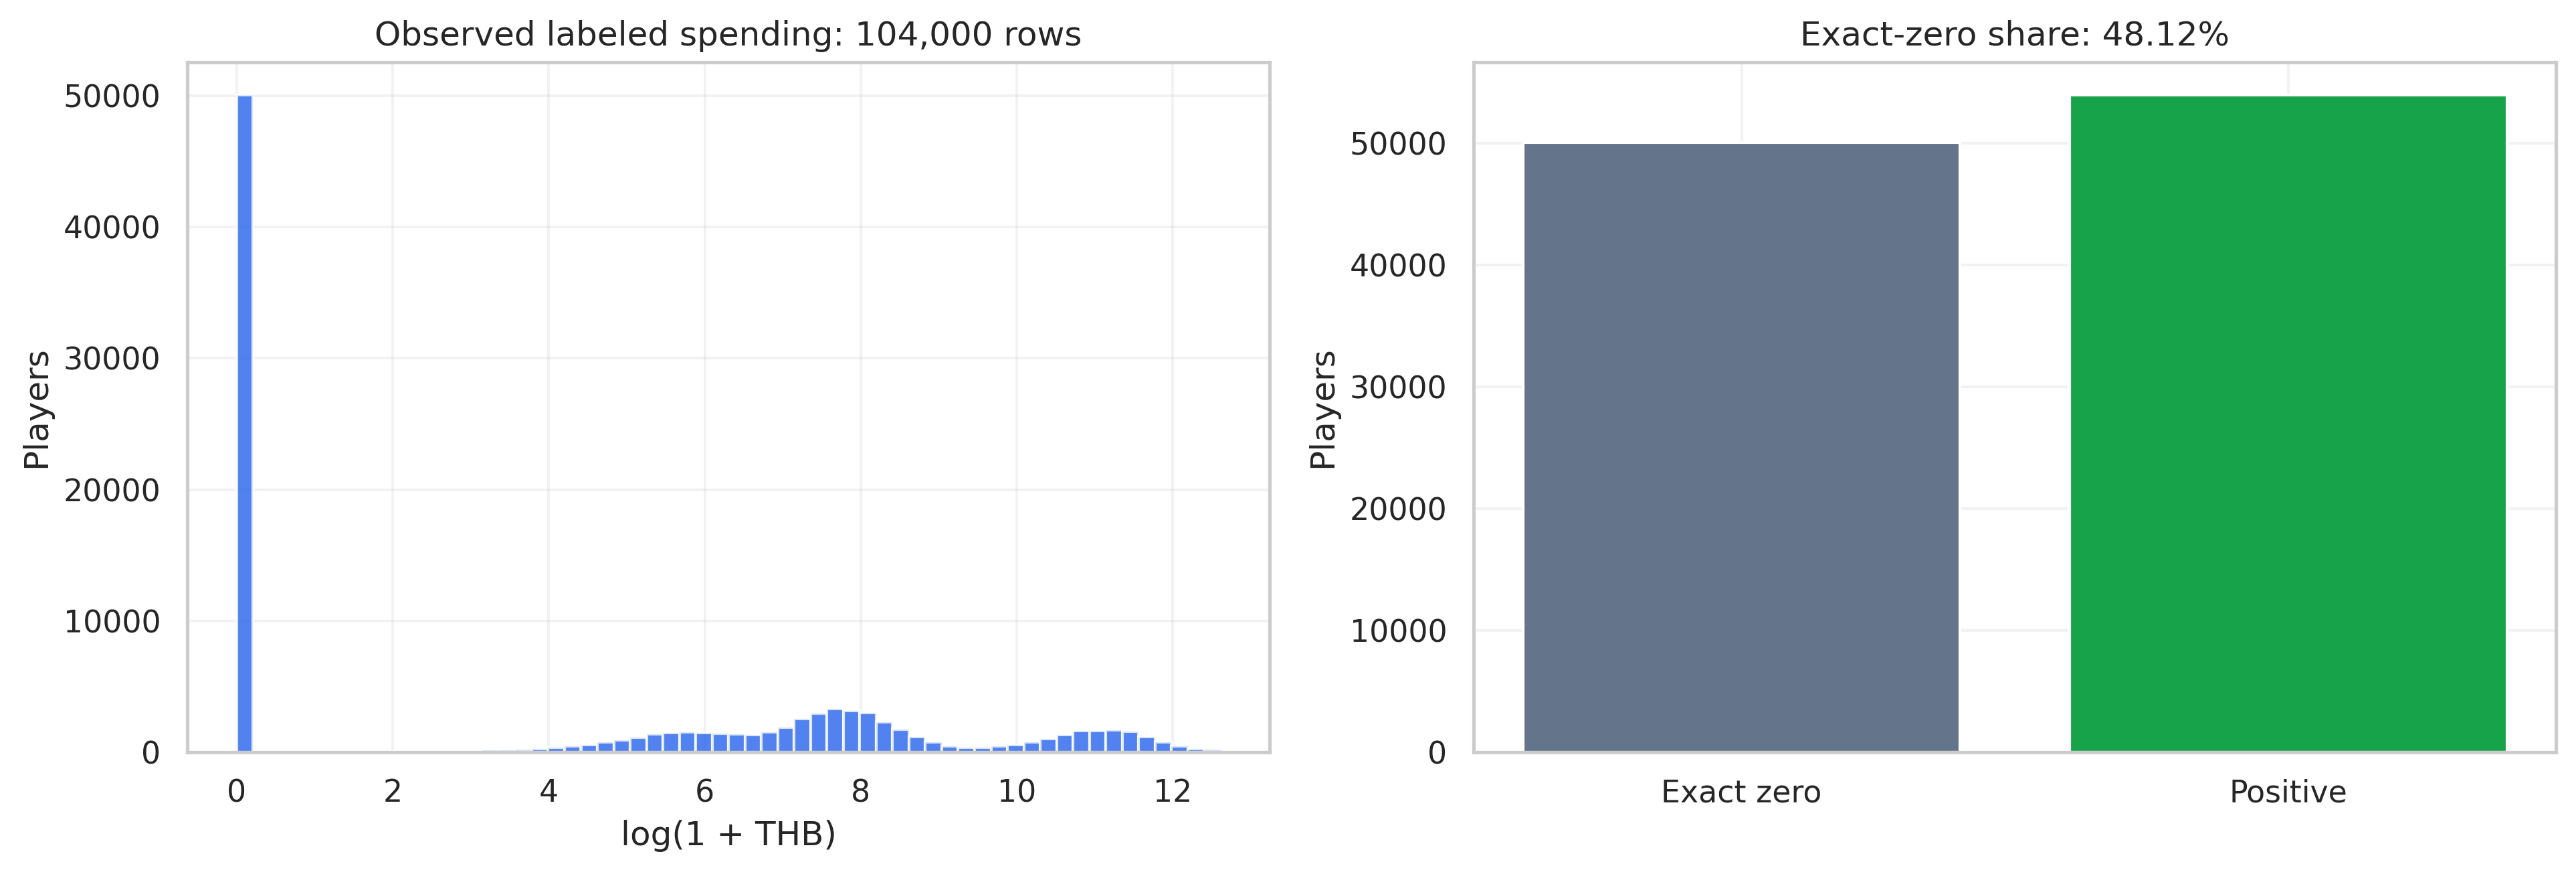

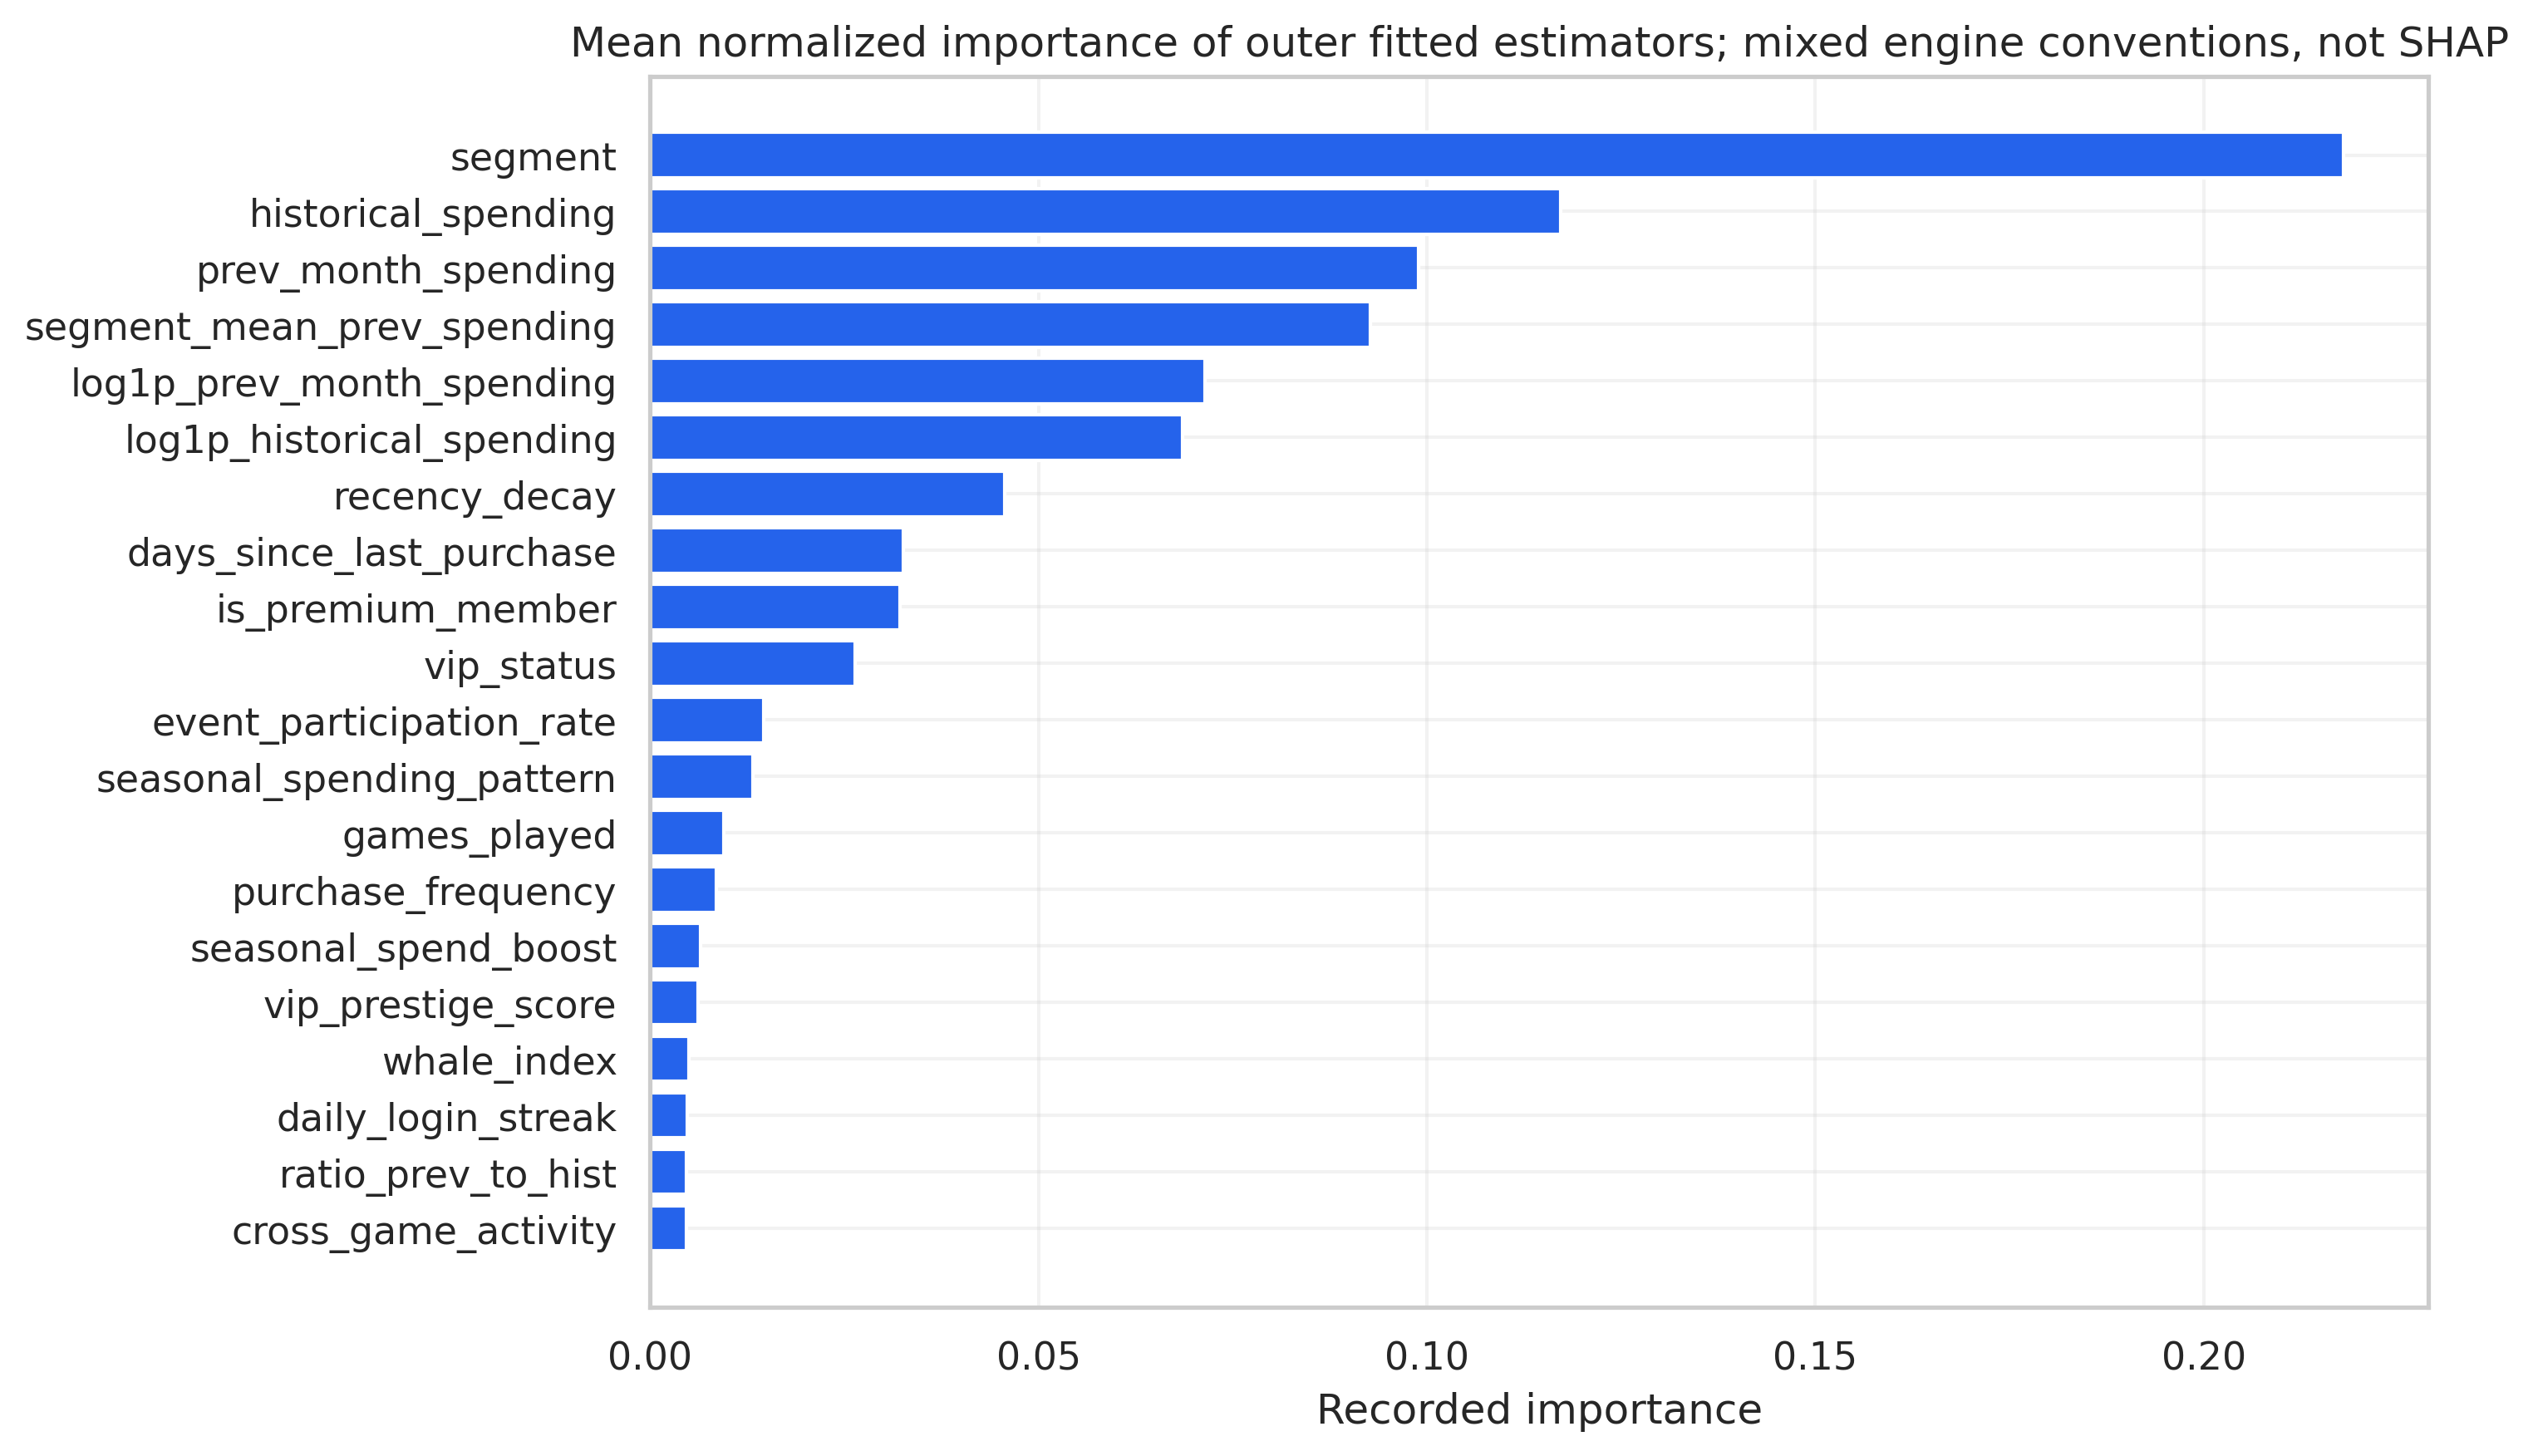

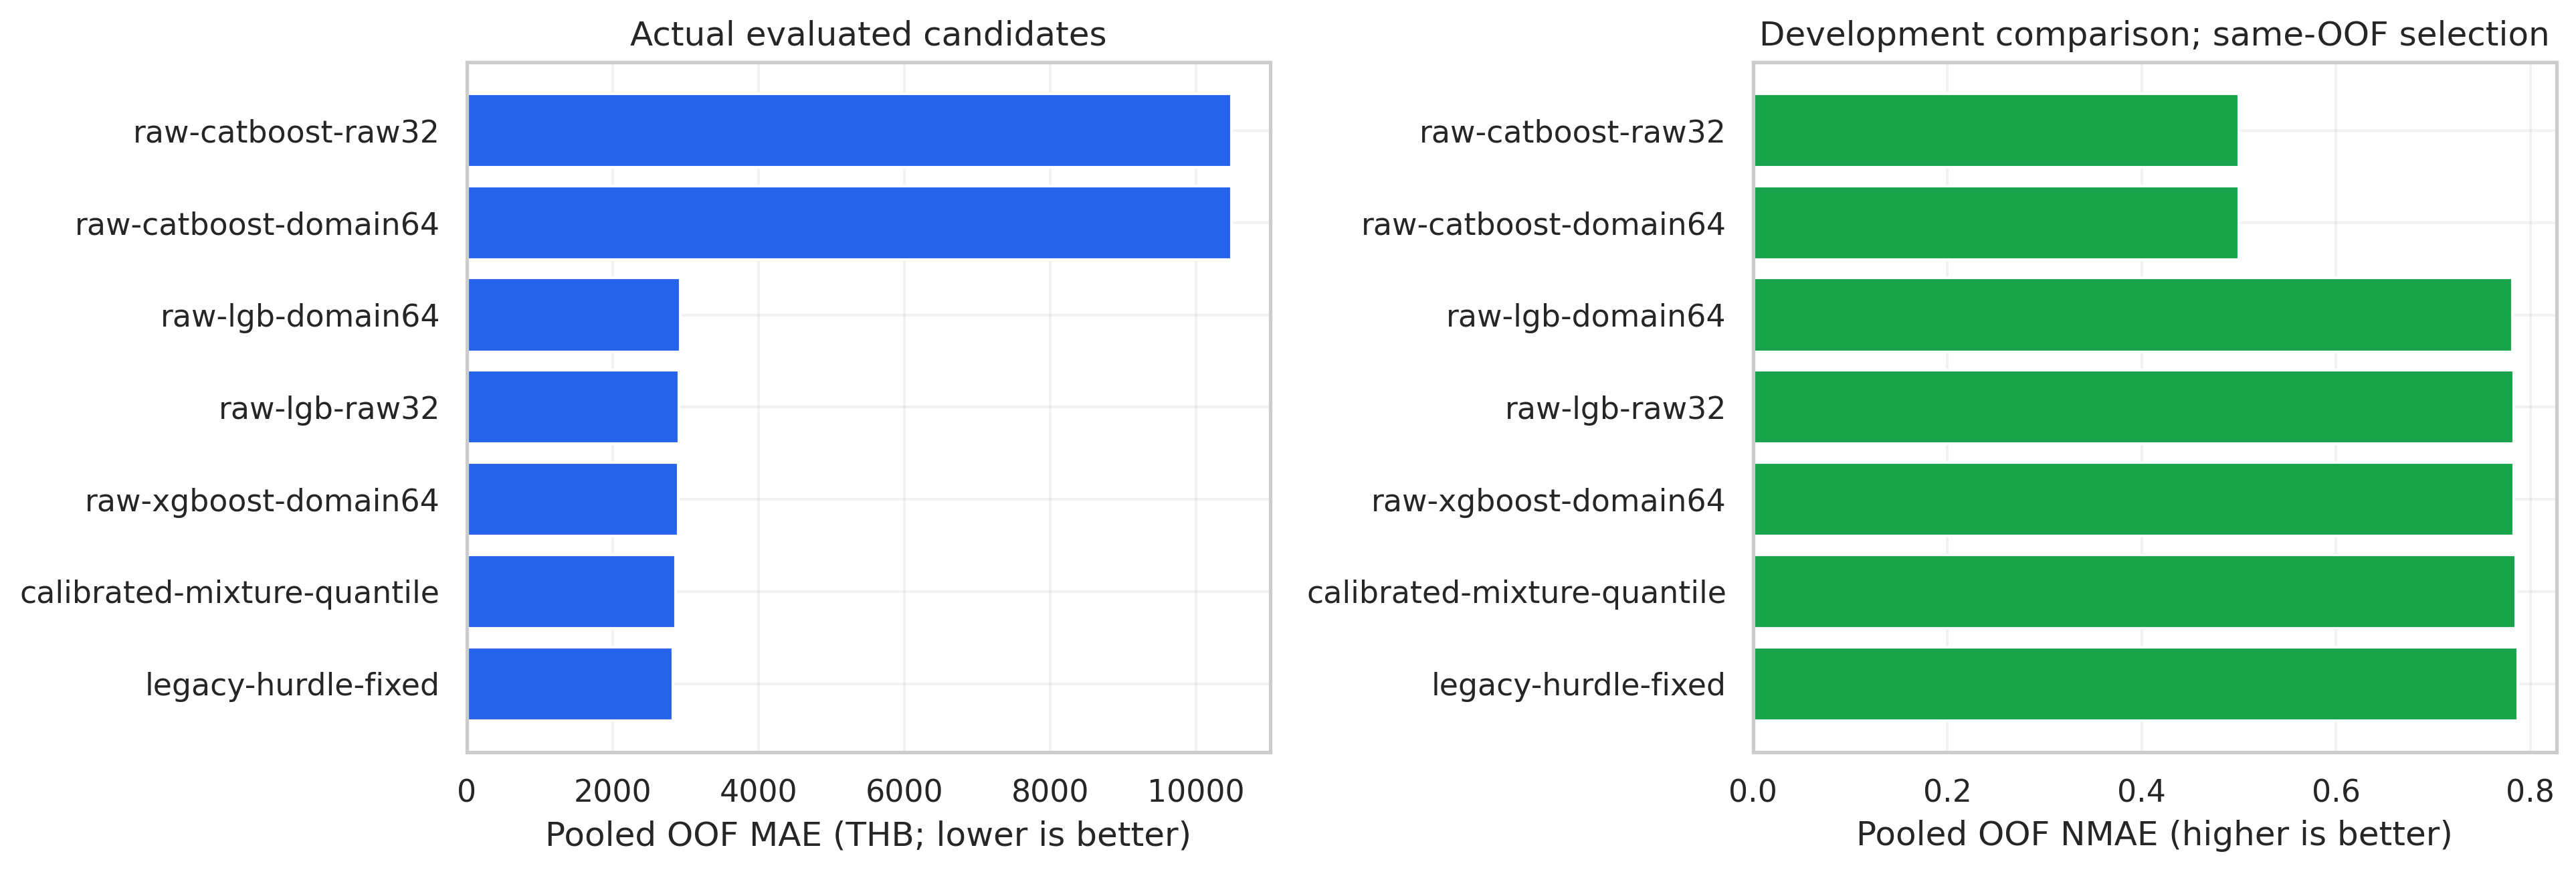

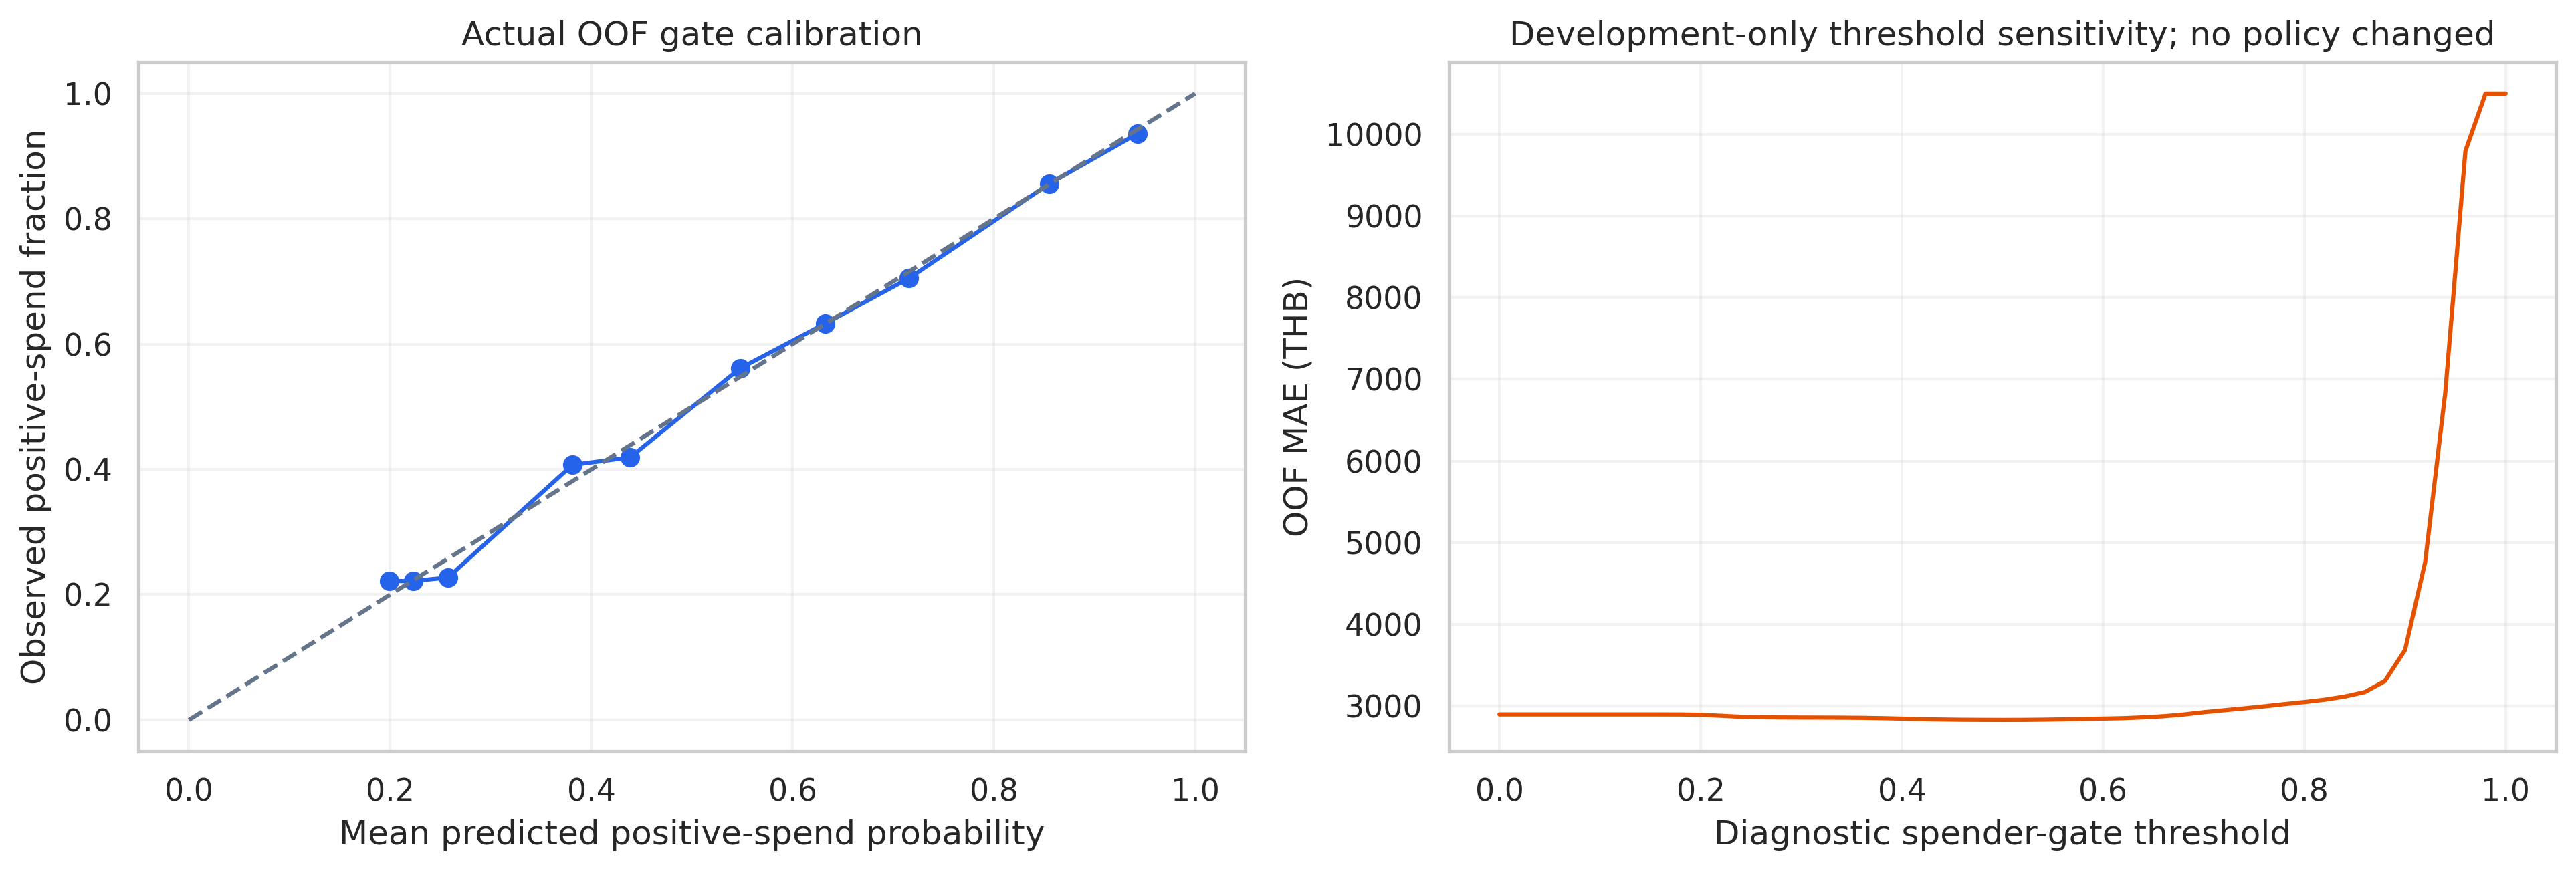

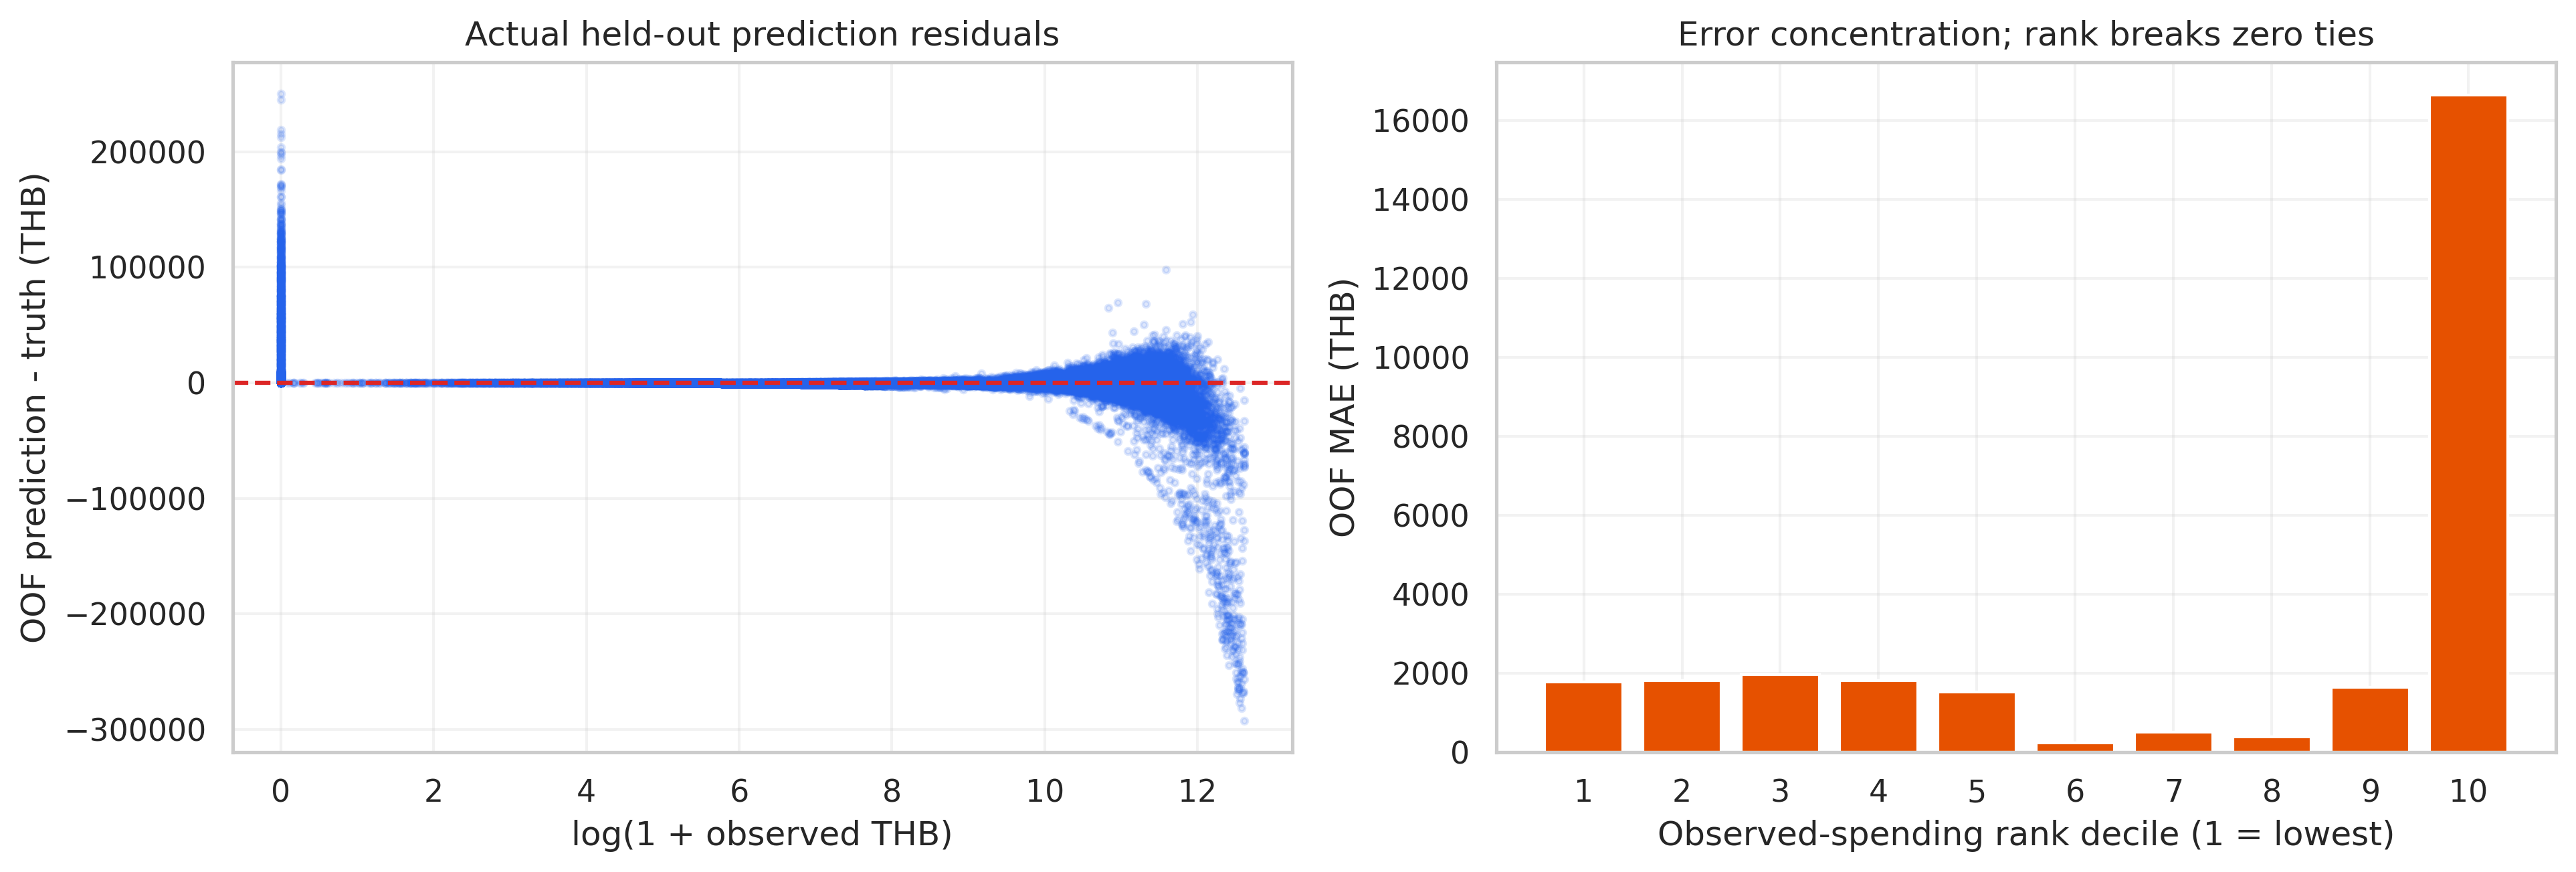

In [9]:
# @title Audit actual evidence, generate report assets, and export the candidate bundle
export = audit_and_export(ctx, results, CFG, RUN_DIR)
summary = pd.read_csv(RUN_DIR / 'assets/model-ablation-comparison.csv')
display(summary)
print(json.dumps({'winner': export['winner']['name'],
                  'metrics_path': export['paths']['metrics'],
                  'bundle': export['paths']['bundle'],
                  'selection_status': export['metrics']['selection_label'],
                  'independently_confirmed': export['metrics']['independently_confirmed'],
                  'submission_status': 'NOT SUBMITTED; team-wide audit and exact-file approval still required'}, indent=2))
for image in sorted((RUN_DIR / 'assets').glob('*.png')):
    from IPython.display import Image, display
    display(Image(filename=str(image), width=1100))

In [10]:
# @title Download the reviewed bundle (Colab) or inspect its local path
if IN_COLAB and os.environ.get('TASK3_AUTO_DOWNLOAD', '1') == '1':
    from google.colab import files
    files.download(export['paths']['bundle'])
else:
    print('Bundle ready:', export['paths']['bundle'])

Bundle ready: /content/ml004-task3/runs/task3-a100-quantile-v1/colab_export_task3.zip


## Evaluation answer card

- **Metric:** higher-is-better pooled OOF NMAE, raw THB; per-fold MAE/NMAE and standard deviation are exported.
- **Data:** actual supplied files and hashes are in run-manifest.json; missing Validation provenance remains explicit.
- **Leakage controls:** outer holdouts are never fit; calibration uses inner OOF; Test is inference/QA only.
- **Selection:** the best measured candidate is a development selection, not an independently confirmed score.
- **Outputs:** 25,889 canonical IDs; finite nonnegative THB; submission and test CSV values match exactly.
- **Reproducibility:** pinned packages, source/data/fold hashes, backend information and actual fitted checkpoints.
- **Kaggle status:** no submission; team-wide readiness and exact-file approval are separate final steps.